# Installing Dependencies

In [1]:
!uv pip install braindecode torch torchinfo torchvision torchaudio mne numpy scipy seaborn scikit-learn matplotlib

Using Python 3.13.15 environment at: /usr
Resolved 94 packages in 1.60s
Prepared 13 packages in 83ms
Installed 13 packages in 18ms
 + axial-positional-embedding==0.3.12
 + braindecode==1.8.1
 + colt5-attention==0.11.2
 + docstring-inheritance==3.0.0
 + hyper-connections==0.4.11
 + linear-attention-transformer==0.19.1
 + linformer==0.2.3
 + local-attention==1.11.2
 + mne-bids==0.20.0
 + product-key-memory==0.3.0
 + skorch==1.4.0
 + torch-einops-utils==0.1.36
 + wfdb==4.3.1


# Importing

In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchinfo import summary
import torch.nn.functional as F
from torch.utils.data import Dataset
from torch.utils.data import TensorDataset, DataLoader
from torch.nn.utils.parametrize import register_parametrization

import mne
import numpy as np
import seaborn as sns
import scipy.io as sio
import scipy.signal as signal
import matplotlib.pyplot as plt
from scipy.signal import butter, sosfilt
from sklearn.metrics import confusion_matrix

In [3]:
# from braindecode.models import EEGTCNet, EEGTCNet, EEGConformer
# from braindecode.models import EEGConformer as BraindecoderEEGConformer
# from braindecode.models import EEGNet as BraindecoderEEGNet

# Preprocessing

In [4]:
class BCICausalPreprocessor:
    def __init__(self, lowcut=8.0, highcut=30.0, fs=250):
        self.fs = fs
        self.lowcut = lowcut
        self.highcut = highcut
        self.eog_weights = None  
        
        # Design the causal IIR filter (Butterworth)
        self.b, self.a = signal.butter(4, [self.lowcut, self.highcut], btype='bandpass', fs=self.fs)


    def fit_eog_regression(self, eeg_data, eog_data):
        """Calculates the regression weights to subtract EOG from EEG."""
        eog_with_bias = np.vstack([eog_data, np.ones(eog_data.shape[1])])
        eog_cov = np.linalg.pinv(eog_with_bias @ eog_with_bias.T)
        self.eog_weights = eog_cov @ eog_with_bias @ eeg_data.T
        return self.eog_weights


    def apply_eog_regression(self, eeg_data, eog_data):
        """Applies the learned weights to remove EOG artifacts."""
        if self.eog_weights is None:
            raise ValueError("Fit the preprocessor on training data first!")
            
        eog_with_bias = np.vstack([eog_data, np.ones(eog_data.shape[1])])
        eeg_clean = eeg_data - (self.eog_weights.T @ eog_with_bias)
        return eeg_clean


    def causal_filter(self, data):
        """Applies a strictly causal filter using scipy.signal.lfilter."""
        filtered_data = signal.lfilter(self.b, self.a, data, axis=-1)
        return filtered_data


    def process_file(self, filepath, is_training=True):
        """Loads a GDF file, handles NaNs, removes EOG, and causally filters."""
        raw = mne.io.read_raw_gdf(filepath, preload=True)
        data = raw.get_data()
        
        # Handle NaNs
        data = np.nan_to_num(data, nan=0.0)
        
        # Split EEG (first 22) and EOG (last 3)
        eeg_data = data[:22, :]
        eog_data = data[22:25, :]
        
        # EOG Artifact Removal
        if is_training:
            self.fit_eog_regression(eeg_data, eog_data)
        eeg_clean = self.apply_eog_regression(eeg_data, eog_data)
        
        # Causal Filtering
        eeg_filtered = self.causal_filter(eeg_clean)
        
        # Extract Events AND the event dictionary
        events, event_dict = mne.events_from_annotations(raw)
        
        return eeg_filtered, events, event_dict


    @staticmethod
    def generate_causal_windows(eeg_filtered, events, event_dict, window_size_sec=2.0, fs=250, is_training=True):
        window_samples = int(window_size_sec * fs)
        
        # Motor imagery typically happens 0.5s to 3.5s AFTER the cue
        # BCI Comp IV 2a cues are at t=2s of the trial structure, MI lasts until t=6s.
        offset_start = int(0.5 * fs) 
        offset_end = int(3.5 * fs)   
        stride = int(0.2 * fs) # 200ms stride (50 samples) drastically reduces redundancy
        
        total_samples = eeg_filtered.shape[1]
        mne_id_to_gdf_str = {v: k for k, v in event_dict.items()}
        
        if is_training:
            target_events = {'769': 0, '770': 1, '771': 2, '772': 3}
        else:
            target_events = {'783': -1} 
        
        X_windows, y_labels, time_indices = [], [], []
        
        for event in events:
            sample_idx = event[0]
            mne_event_id = event[2] 
            gdf_event_str = mne_id_to_gdf_str.get(mne_event_id, "")
            
            if gdf_event_str in target_events:
                label = target_events[gdf_event_str]
                
                # Start and end relative to the cue
                start_idx = sample_idx + offset_start
                end_idx = sample_idx + offset_end
                
                for t in range(start_idx + window_samples, end_idx, stride):
                    if t <= total_samples:
                        window = eeg_filtered[:, t - window_samples : t]
                        
                        if window.shape[1] == window_samples:
                            X_windows.append(window)
                            y_labels.append(label)
                            time_indices.append((t - start_idx) / fs)
                        
        return np.array(X_windows, dtype=np.float32), np.array(y_labels, dtype=np.int64), np.array(time_indices, dtype=np.float32)


# Model

In [5]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class NM_PINN(nn.Module):
    def __init__(self, num_channels=22, F1=8, D=2, num_classes=4, fs=250, pool_factor=8):
        super(NM_PINN, self).__init__()
        self.F1 = F1
        self.D = D  
        self.fs = fs
        self.pool_factor = pool_factor  
        self.dt_phys = pool_factor / fs 
        
        assert D == 2, "D must be 2 to split spatial features into Excitatory and Inhibitory pairs."

        kernel_length = fs // 2
        self.temp_conv = nn.Conv2d(1, F1, kernel_size=(1, kernel_length), padding='same', bias=False)
        self.bn1 = nn.BatchNorm2d(F1)
        self.depthwise = nn.Conv2d(F1, F1 * D, kernel_size=(num_channels, 1), groups=F1, bias=False)
        self.bn2 = nn.BatchNorm2d(F1 * D)
        self.activation = nn.ELU()

        # --- Macroscopic Physics Parameters ---
        self.tau_E = nn.Parameter(torch.full((1, F1, 1), 0.01))
        self.tau_I = nn.Parameter(torch.full((1, F1, 1), 0.01))
        self.w_EE = nn.Parameter(torch.full((1, F1, 1), 1.2))
        self.w_EI = nn.Parameter(torch.full((1, F1, 1), 1.0))
        self.w_IE = nn.Parameter(torch.full((1, F1, 1), 1.0))
        self.w_II = nn.Parameter(torch.full((1, F1, 1), 0.5))
        self.P = nn.Parameter(torch.zeros(1, F1, 1))
        self.Q = nn.Parameter(torch.zeros(1, F1, 1))

        self.avg_pool = nn.AdaptiveAvgPool2d((1, 1)) 
        self.dropout = nn.Dropout(p=0.5)
        
        # --- FUSED CLASSIFIER ---
        # x_pool (16) + E_feat (8) + I_feat (8) = 32 dimensions
        fused_feature_dim = (F1 * D) + F1 + F1 
        self.classifier = nn.Linear(fused_feature_dim, num_classes)
        self._init_weights()

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
            elif isinstance(m, nn.Linear):
                nn.init.xavier_uniform_(m.weight)
                if m.bias is not None:
                    nn.init.zeros_(m.bias)

    def compute_wc_loss(self, E, I):
        tE = F.softplus(self.tau_E); tI = F.softplus(self.tau_I)
        wEE = F.softplus(self.w_EE); wEI = F.softplus(self.w_EI)
        wIE = F.softplus(self.w_IE); wII = F.softplus(self.w_II)

        dE_dt = (E[:, :, 1:] - E[:, :, :-1]) / self.dt_phys
        dI_dt = (I[:, :, 1:] - I[:, :, :-1]) / self.dt_phys
        E_t = E[:, :, :-1]; I_t = I[:, :, :-1]

        drv_E = wEE * E_t - wEI * I_t + self.P
        drv_I = wIE * E_t - wII * I_t + self.Q

        res_E = tE * dE_dt + E_t - torch.sigmoid(drv_E)
        res_I = tI * dI_dt + I_t - torch.sigmoid(drv_I)
        return torch.mean(res_E ** 2) + torch.mean(res_I ** 2)

    def compute_orthogonality_loss(self):
        """ Penalize spatial correlation to force distinct biological representations. """
        weights = self.depthwise.weight.squeeze() # Shape: (16, 22)
        
        W_E = weights[:self.F1, :] # Shape: (8, 22)
        W_I = weights[self.F1:, :] # Shape: (8, 22)
        
        W_E_norm = F.normalize(W_E, p=2, dim=1)
        W_I_norm = F.normalize(W_I, p=2, dim=1)
        
        similarity = torch.sum(W_E_norm * W_I_norm, dim=1)
        return torch.mean(similarity ** 2)

    def forward(self, x):
        if len(x.shape) == 3: x = x.unsqueeze(1)
        
        # 1. Base Feature Extraction
        x = self.bn1(self.temp_conv(x))
        x_main = self.activation(self.bn2(self.depthwise(x)))

        # 2. Physics Branch Processing
        x_phys = F.avg_pool1d(x_main.squeeze(2), self.pool_factor)
        E_phys = torch.sigmoid(x_phys[:, :self.F1, :])
        I_phys = torch.sigmoid(x_phys[:, self.F1:, :])
        
        # 3. Calculate Regularization Losses
        loss_wc = self.compute_wc_loss(E_phys, I_phys)
        loss_ortho = self.compute_orthogonality_loss()

        # 4. Feature Fusion
        E_feat = E_phys.mean(dim=-1)
        I_feat = I_phys.mean(dim=-1)
        x_pool = self.avg_pool(x_main).squeeze(-1).squeeze(-1) 
        
        # Concatenate: (Batch, 16) + (Batch, 8) + (Batch, 8) -> (Batch, 32)
        fused_features = self.dropout(torch.cat([x_pool, E_feat, I_feat], dim=-1))
        
        # 5. Final Classification
        logits = self.classifier(fused_features)
        
        return logits, loss_wc, loss_ortho
'''
====================================================================================================
Layer (type:depth-idx)                   Input Shape          Output Shape         Param #
====================================================================================================
NM_PINN                                  [64, 22, 500]        [64, 4]              64
├─Conv2d: 1-1                            [64, 1, 22, 500]     [64, 8, 22, 500]     1,000
├─BatchNorm2d: 1-2                       [64, 8, 22, 500]     [64, 8, 22, 500]     16
├─Conv2d: 1-3                            [64, 8, 22, 500]     [64, 16, 1, 500]     352
├─BatchNorm2d: 1-4                       [64, 16, 1, 500]     [64, 16, 1, 500]     32
├─ELU: 1-5                               [64, 16, 1, 500]     [64, 16, 1, 500]     --
├─AdaptiveAvgPool2d: 1-6                 [64, 16, 1, 500]     [64, 16, 1, 1]       --
├─Dropout: 1-7                           [64, 32]             [64, 32]             --
├─Linear: 1-8                            [64, 32]             [64, 4]              132
====================================================================================================
Total params: 1,596
Trainable params: 1,596
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 715.28
====================================================================================================
Input size (MB): 2.82
Forward/backward pass size (MB): 98.31
Params size (MB): 0.01
Estimated Total Size (MB): 101.13
====================================================================================================
'''

'\n====================================================================================================\nLayer (type:depth-idx)                   Input Shape          Output Shape         Param #\n====================================================================================================\nNM_PINN                                  [64, 22, 500]        [64, 4]              64\n├─Conv2d: 1-1                            [64, 1, 22, 500]     [64, 8, 22, 500]     1,000\n├─BatchNorm2d: 1-2                       [64, 8, 22, 500]     [64, 8, 22, 500]     16\n├─Conv2d: 1-3                            [64, 8, 22, 500]     [64, 16, 1, 500]     352\n├─BatchNorm2d: 1-4                       [64, 16, 1, 500]     [64, 16, 1, 500]     32\n├─ELU: 1-5                               [64, 16, 1, 500]     [64, 16, 1, 500]     --\n├─AdaptiveAvgPool2d: 1-6                 [64, 16, 1, 500]     [64, 16, 1, 1]       --\n├─Dropout: 1-7                           [64, 32]             [64, 32]             --\n├

# Train Eval loop

In [6]:
def NM_train_eval(subject, model, batch_size, criterion, optimizer, epochs, device, preprocessor, lambda_ortho, max_lambda):

    print("\nProcessing Training Data...")
    train_file = f'/kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A0{subject}T.gdf'
    train_eeg, train_events, train_dict = preprocessor.process_file(train_file, is_training=True)

    X_train, y_train, _ = BCICausalPreprocessor.generate_causal_windows(
        train_eeg, train_events, train_dict, window_size_sec=2.0, is_training=True
    )

    train_mean = np.mean(X_train, axis=(0, 2), keepdims=True)
    train_std = np.std(X_train, axis=(0, 2), keepdims=True) + 1e-8
    X_train_norm = (X_train - train_mean) / train_std

    train_loader = DataLoader(
            TensorDataset(torch.tensor(X_train_norm, dtype=torch.float32), 
                          torch.tensor(y_train, dtype=torch.long)),
            batch_size=batch_size, shuffle=True
        )

    model = model.to(device)
    for epoch in range(1, epochs+1):
        model.train()
        total_loss = running_ce_loss = running_wc_loss = running_ortho_loss = 0.0
        correct = 0
        total = 0
                
        current_lambda_wc = 0.0 if epoch < 10 else max_lambda * ((epoch - 10) / (epochs - 10))


        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
        
            optimizer.zero_grad()
            logits, wc_loss, ortho_loss = model(inputs)
        
            ce_loss = criterion(logits, labels)
            total_loss = ce_loss + (current_lambda_wc * wc_loss) + (lambda_ortho * ortho_loss)
        
            total_loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()

            running_ce_loss += ce_loss.item()
            running_wc_loss += wc_loss.item()
            running_ortho_loss += ortho_loss.item()
        
            _, predicted = torch.max(logits.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
        

        if (epoch + 1) % 10 == 0 or epoch == 0:
            train_acc = 100 * correct / total
            print(f"Epoch [{epoch+1}/{epochs}] | "
                f"CE Loss: {total_loss/len(train_loader):.4f} | "
                f"WC Loss: {running_wc_loss/len(train_loader):.4f} | "
                f"Ortho Loss: {running_ortho_loss/len(train_loader):.4f} | "
                f"Train Acc: {train_acc:.2f}%")
            if (epoch+1)==epochs:
                print(f"\n{'='*50}")
                print(f"🏆 OFFICIAL FINAL TRAINING RESULTS (T)")
                print(f"{'='*50}")
                print(f"CE Loss: {total_loss/len(train_loader):.4f}")
                print(f"WC Loss: {running_wc_loss/len(train_loader):.4f} | ")
                print(f"Ortho Loss: {running_ortho_loss/len(train_loader):.4f} | ")
                print(f"Train Acc: {train_acc:.2f}%")
                print(f"{'='*50}\n")

    print(f"Running Official Holdout Evaluation (Session T -> Session E) on device: {device}\n")
    print("Loading official evaluation true labels...")
    mat_path = f"/kaggle/input/datasets/abdelrahmanyousryyu/bci-competition-iv-data-sets-2a-true-labels/A0{subject}E.mat"

    mat_data = sio.loadmat(mat_path)

    # proccessing file data
    if 'classlabel' in mat_data:
        true_trial_labels = mat_data['classlabel'].flatten()
    elif 'labels' in mat_data:
        true_trial_labels = mat_data['labels'].flatten()
    else:
        for key, val in mat_data.items():
            if isinstance(val, np.ndarray) and val.flatten().shape[0] in [288, 43198]:
                true_trial_labels = val.flatten()
                break
                
    if true_trial_labels.min() == 1:
        true_trial_labels = true_trial_labels - 1

    print(f"Successfully loaded {len(true_trial_labels)} trial-level true keys.")



    print(f"\n=== Processing Subject {subject} Evaluation GDF ===")
    eval_file = f'/kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A0{subject}E.gdf'

    eval_eeg, eval_events, eval_dict = preprocessor.process_file(eval_file, is_training=False)
    X_eval, _, t_eval = BCICausalPreprocessor.generate_causal_windows(eval_eeg, eval_events, eval_dict, is_training=False)

    # Normalize Evaluation windows using TRAINING stats
    print("Applying global training normalization to evaluation data...")
    X_eval_norm = (X_eval - train_mean) / train_std

    print("Reconstructing trial indices from the relative timeline clock...")

    trial_mappings = np.zeros(len(t_eval), dtype=np.int64)
    current_trial_idx = 0

    for i in range(1, len(t_eval)):
        if t_eval[i] < t_eval[i-1] or t_eval[i] == 0.0:
            current_trial_idx += 1
        
        if current_trial_idx >= len(true_trial_labels):
            current_trial_idx = len(true_trial_labels) - 1
            
        trial_mappings[i] = current_trial_idx

    y_eval_true = true_trial_labels[trial_mappings]

    print(f"Labels successfully aligned! Verification Shape: {y_eval_true.shape}")
    print(f"Total unique trials reconstructed from timeline: {len(np.unique(trial_mappings))}/288")

    eval_loader = DataLoader(
        TensorDataset(torch.tensor(X_eval_norm, dtype=torch.float32), torch.tensor(y_eval_true, dtype=torch.long)),
        batch_size=64, shuffle=False
    )

    model.eval()

    # Dictionary to accumulate logits per trial
    trial_logits_accumulator = {i: [] for i in range(len(true_trial_labels))}

    with torch.no_grad():
        window_idx = 0 
        for inputs, labels in eval_loader:
            inputs = inputs.to(device)
            logits, wc_loss, ortho_loss = model(inputs)
            
            logits_cpu = logits.cpu().numpy()
            
            for batch_i in range(logits.size(0)):
                current_trial = trial_mappings[window_idx]
                trial_logits_accumulator[current_trial].append(logits_cpu[batch_i])
                window_idx += 1

    # Aggregate and score
    eval_correct = 0
    all_true_labels = []
    all_pred_labels = []

    for trial_id, logit_list in trial_logits_accumulator.items():
        if len(logit_list) == 0:
            continue
                    
        # Sum/Mean all window logits within the trial
        mean_logits = np.mean(logit_list, axis=0)
        predicted_class = np.argmax(mean_logits)
        true_class = true_trial_labels[trial_id]
            
        # Store for the confusion matrix
        all_true_labels.append(true_class)
        all_pred_labels.append(predicted_class)
            
        if predicted_class == true_class:
            eval_correct += 1

    final_holdout_acc = 100 * eval_correct / len(true_trial_labels)

    print(f"\n{'='*50}")
    print(f"🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)")
    print(f"{'='*50}")
    print(f"Target Subject File:  A0{subject}E.gdf")
    print(f"Total True Trials:    {len(true_trial_labels)}")
    print(f"Final True Test Acc:  {final_holdout_acc:.2f}%")
    print(f"{'='*50}\n")

    class_names = ['Left Hand', 'Right Hand', 'Both Feet', 'Tongue']

    cm = confusion_matrix(all_true_labels, all_pred_labels)

    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                xticklabels=class_names, 
                yticklabels=class_names,
                annot_kws={"size": 14})

    plt.title(f'Holdout Confusion Matrix (Acc: {final_holdout_acc:.1f}%)', fontsize=14, pad=15)
    plt.xlabel('Predicted MI Class', fontsize=12, labelpad=10)
    plt.ylabel('True MI Class', fontsize=12, labelpad=10)
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()
    return final_holdout_acc

# Parameters

In [7]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Initializing Preprocessor...")
preprocessor = BCICausalPreprocessor(lowcut=8.0, highcut=30.0)
batch_size = 64
epochs = 300
lists = []
parameters = (22, 8, 2, 4, 250, 16)


Initializing Preprocessor...


# Train & Eval

In [8]:
def run_(subject, parameters, batch_size, epochs, device, preprocessor, lambda_ortho, max_lambda):
    list = []
    for i in range(5):
        model = NM_PINN(*parameters)
        criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
        physics_param_names = {'tau_E', 'tau_I', 'w_EE', 'w_EI', 'w_IE', 'w_II', 'P', 'Q'}
        physics_params = [p for n, p in model.named_parameters() if any(x in n for x in physics_param_names)]
        base_params = [p for n, p in model.named_parameters() if not any(x in n for x in physics_param_names)]

        optimizer = optim.AdamW([
            {'params': base_params, 'lr': 8e-4},
            {'params': physics_params, 'lr': 1e-5}
        ], weight_decay=1e-3)
        list.append(NM_train_eval(subject, model, batch_size, criterion, optimizer, epochs, device, preprocessor, lambda_ortho, max_lambda))
        print(f"End of {i+1}")
        print("="*200)
    return list

## Subject 1


Processing Training Data...
Extracting GDF parameters from /kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A01T.gdf...
Setting channel info structure...
Could not determine channel type of the following channels, they will be set as EEG:
EEG-Fz, EEG, EEG, EEG, EEG, EEG, EEG, EEG-C3, EEG, EEG-Cz, EEG, EEG-C4, EEG, EEG, EEG, EEG, EEG, EEG, EEG, EEG-Pz, EEG, EEG, EOG-left, EOG-central, EOG-right
Creating raw.info structure...
Reading 0 ... 672527  =      0.000 ...  2690.108 secs...


/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '769', '770', '771', '772']
Epoch [10/300] | CE Loss: 0.0581 | WC Loss: 1.7531 | Ortho Loss: 0.0165 | Train Acc: 39.10%
Epoch [20/300] | CE Loss: 0.0544 | WC Loss: 1.3808 | Ortho Loss: 0.0094 | Train Acc: 49.38%
Epoch [30/300] | CE Loss: 0.0441 | WC Loss: 1.4121 | Ortho Loss: 0.0100 | Train Acc: 57.57%
Epoch [40/300] | CE Loss: 0.0421 | WC Loss: 1.4547 | Ortho Loss: 0.0129 | Train Acc: 63.96%
Epoch [50/300] | CE Loss: 0.0465 | WC Loss: 1.5387 | Ortho Loss: 0.0147 | Train Acc: 69.17%
Epoch [60/300] | CE Loss: 0.0383 | WC Loss: 1.5224 | Ortho Loss: 0.0179 | Train Acc: 70.76%
Epoch [70/300] | CE Loss: 0.0405 | WC Loss: 1.5482 | Ortho Loss: 0.0236 | Train Acc: 71.94%
Epoch [80/300] | CE Loss: 0.0357 | WC Loss: 1.6056 | Ortho Loss: 0.0274 | Train Acc: 74.86%
Epoch [90/300] | CE Loss: 0.0366 | WC Loss: 1.5980 | Ortho Loss: 0.0282 | Train Acc: 75.69%
Epoch [100/300] | CE Loss: 0.0391 | WC Loss: 1.6087 | Ortho Loss: 

/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '783']
Applying global training normalization to evaluation data...
Reconstructing trial indices from the relative timeline clock...
Labels successfully aligned! Verification Shape: (1440,)
Total unique trials reconstructed from timeline: 288/288

🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)
Target Subject File:  A01E.gdf
Total True Trials:    288
Final True Test Acc:  81.94%



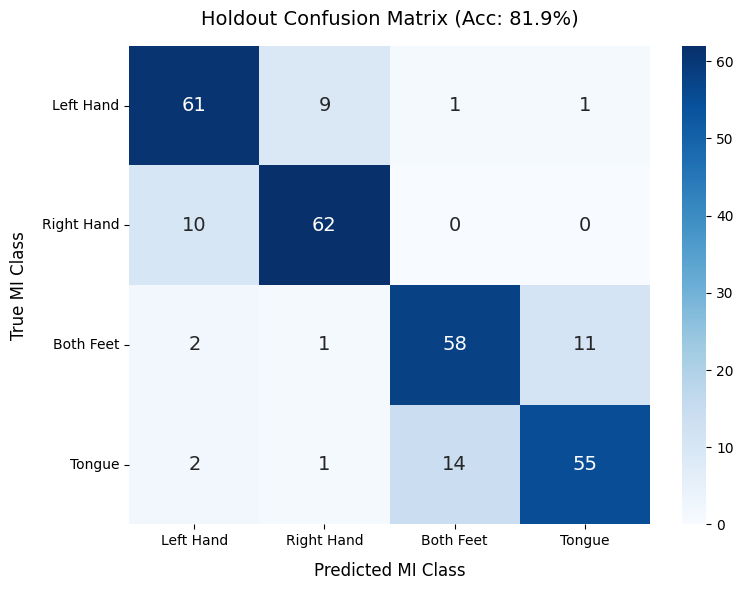

End of 1

Processing Training Data...
Extracting GDF parameters from /kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A01T.gdf...
Setting channel info structure...
Could not determine channel type of the following channels, they will be set as EEG:
EEG-Fz, EEG, EEG, EEG, EEG, EEG, EEG, EEG-C3, EEG, EEG-Cz, EEG, EEG-C4, EEG, EEG, EEG, EEG, EEG, EEG, EEG, EEG-Pz, EEG, EEG, EOG-left, EOG-central, EOG-right
Creating raw.info structure...
Reading 0 ... 672527  =      0.000 ...  2690.108 secs...


/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '769', '770', '771', '772']
Epoch [10/300] | CE Loss: 0.0565 | WC Loss: 2.0080 | Ortho Loss: 0.0323 | Train Acc: 38.06%
Epoch [20/300] | CE Loss: 0.0506 | WC Loss: 1.8769 | Ortho Loss: 0.0336 | Train Acc: 48.19%
Epoch [30/300] | CE Loss: 0.0445 | WC Loss: 1.7980 | Ortho Loss: 0.0391 | Train Acc: 55.00%
Epoch [40/300] | CE Loss: 0.0412 | WC Loss: 1.7808 | Ortho Loss: 0.0402 | Train Acc: 59.79%
Epoch [50/300] | CE Loss: 0.0420 | WC Loss: 1.8530 | Ortho Loss: 0.0411 | Train Acc: 66.18%
Epoch [60/300] | CE Loss: 0.0376 | WC Loss: 1.8934 | Ortho Loss: 0.0389 | Train Acc: 69.17%
Epoch [70/300] | CE Loss: 0.0379 | WC Loss: 1.9274 | Ortho Loss: 0.0377 | Train Acc: 71.25%
Epoch [80/300] | CE Loss: 0.0425 | WC Loss: 1.9484 | Ortho Loss: 0.0374 | Train Acc: 73.68%
Epoch [90/300] | CE Loss: 0.0368 | WC Loss: 1.9651 | Ortho Loss: 0.0365 | Train Acc: 74.31%
Epoch [100/300] | CE Loss: 0.0353 | WC Loss: 2.0137 | Ortho Loss: 

/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '783']
Applying global training normalization to evaluation data...
Reconstructing trial indices from the relative timeline clock...
Labels successfully aligned! Verification Shape: (1440,)
Total unique trials reconstructed from timeline: 288/288

🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)
Target Subject File:  A01E.gdf
Total True Trials:    288
Final True Test Acc:  83.33%



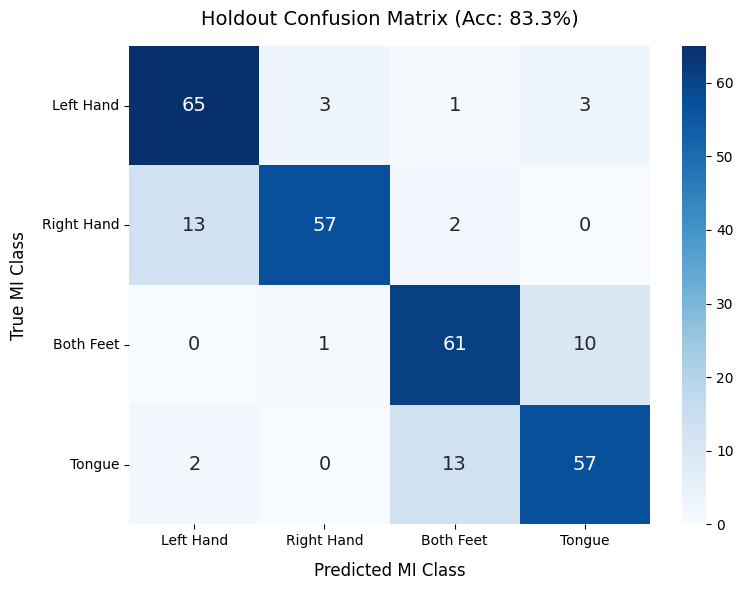

End of 2

Processing Training Data...
Extracting GDF parameters from /kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A01T.gdf...
Setting channel info structure...
Could not determine channel type of the following channels, they will be set as EEG:
EEG-Fz, EEG, EEG, EEG, EEG, EEG, EEG, EEG-C3, EEG, EEG-Cz, EEG, EEG-C4, EEG, EEG, EEG, EEG, EEG, EEG, EEG, EEG-Pz, EEG, EEG, EOG-left, EOG-central, EOG-right
Creating raw.info structure...
Reading 0 ... 672527  =      0.000 ...  2690.108 secs...


/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '769', '770', '771', '772']
Epoch [10/300] | CE Loss: 0.0589 | WC Loss: 1.9304 | Ortho Loss: 0.0114 | Train Acc: 37.78%
Epoch [20/300] | CE Loss: 0.0521 | WC Loss: 1.2821 | Ortho Loss: 0.0179 | Train Acc: 49.44%
Epoch [30/300] | CE Loss: 0.0483 | WC Loss: 1.2920 | Ortho Loss: 0.0233 | Train Acc: 58.47%
Epoch [40/300] | CE Loss: 0.0394 | WC Loss: 1.3466 | Ortho Loss: 0.0252 | Train Acc: 64.86%
Epoch [50/300] | CE Loss: 0.0410 | WC Loss: 1.3992 | Ortho Loss: 0.0251 | Train Acc: 65.69%
Epoch [60/300] | CE Loss: 0.0388 | WC Loss: 1.4046 | Ortho Loss: 0.0231 | Train Acc: 70.35%
Epoch [70/300] | CE Loss: 0.0443 | WC Loss: 1.4003 | Ortho Loss: 0.0202 | Train Acc: 71.74%
Epoch [80/300] | CE Loss: 0.0425 | WC Loss: 1.4554 | Ortho Loss: 0.0178 | Train Acc: 73.12%
Epoch [90/300] | CE Loss: 0.0367 | WC Loss: 1.4352 | Ortho Loss: 0.0157 | Train Acc: 73.89%
Epoch [100/300] | CE Loss: 0.0377 | WC Loss: 1.4759 | Ortho Loss: 

/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '783']
Applying global training normalization to evaluation data...
Reconstructing trial indices from the relative timeline clock...
Labels successfully aligned! Verification Shape: (1440,)
Total unique trials reconstructed from timeline: 288/288

🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)
Target Subject File:  A01E.gdf
Total True Trials:    288
Final True Test Acc:  82.29%



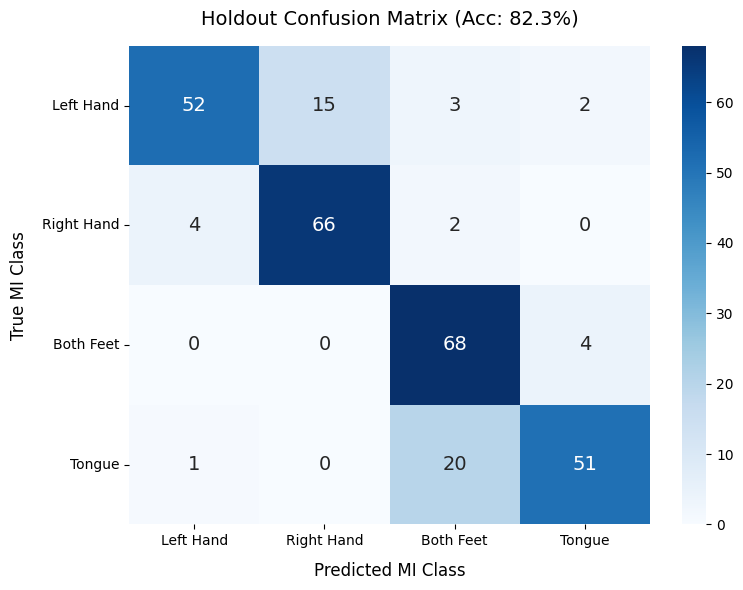

End of 3

Processing Training Data...
Extracting GDF parameters from /kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A01T.gdf...
Setting channel info structure...
Could not determine channel type of the following channels, they will be set as EEG:
EEG-Fz, EEG, EEG, EEG, EEG, EEG, EEG, EEG-C3, EEG, EEG-Cz, EEG, EEG-C4, EEG, EEG, EEG, EEG, EEG, EEG, EEG, EEG-Pz, EEG, EEG, EOG-left, EOG-central, EOG-right
Creating raw.info structure...
Reading 0 ... 672527  =      0.000 ...  2690.108 secs...


/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '769', '770', '771', '772']
Epoch [10/300] | CE Loss: 0.0546 | WC Loss: 1.5027 | Ortho Loss: 0.0100 | Train Acc: 42.43%
Epoch [20/300] | CE Loss: 0.0496 | WC Loss: 1.4333 | Ortho Loss: 0.0036 | Train Acc: 51.04%
Epoch [30/300] | CE Loss: 0.0438 | WC Loss: 1.4965 | Ortho Loss: 0.0033 | Train Acc: 60.97%
Epoch [40/300] | CE Loss: 0.0418 | WC Loss: 1.5767 | Ortho Loss: 0.0061 | Train Acc: 66.25%
Epoch [50/300] | CE Loss: 0.0440 | WC Loss: 1.5867 | Ortho Loss: 0.0073 | Train Acc: 66.53%
Epoch [60/300] | CE Loss: 0.0414 | WC Loss: 1.6428 | Ortho Loss: 0.0079 | Train Acc: 70.76%
Epoch [70/300] | CE Loss: 0.0381 | WC Loss: 1.6841 | Ortho Loss: 0.0093 | Train Acc: 72.57%
Epoch [80/300] | CE Loss: 0.0376 | WC Loss: 1.7255 | Ortho Loss: 0.0108 | Train Acc: 73.19%
Epoch [90/300] | CE Loss: 0.0366 | WC Loss: 1.7560 | Ortho Loss: 0.0116 | Train Acc: 71.53%
Epoch [100/300] | CE Loss: 0.0412 | WC Loss: 1.7851 | Ortho Loss: 

/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '783']
Applying global training normalization to evaluation data...
Reconstructing trial indices from the relative timeline clock...
Labels successfully aligned! Verification Shape: (1440,)
Total unique trials reconstructed from timeline: 288/288

🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)
Target Subject File:  A01E.gdf
Total True Trials:    288
Final True Test Acc:  81.25%



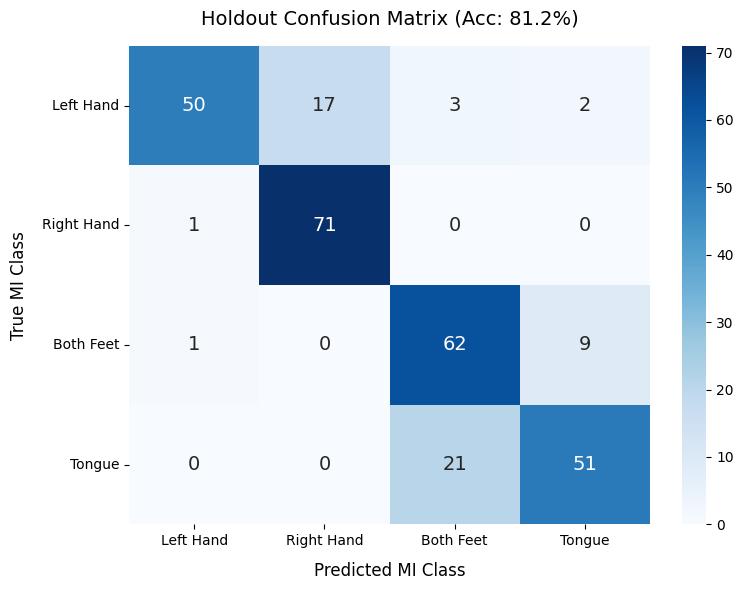

End of 4

Processing Training Data...
Extracting GDF parameters from /kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A01T.gdf...
Setting channel info structure...
Could not determine channel type of the following channels, they will be set as EEG:
EEG-Fz, EEG, EEG, EEG, EEG, EEG, EEG, EEG-C3, EEG, EEG-Cz, EEG, EEG-C4, EEG, EEG, EEG, EEG, EEG, EEG, EEG, EEG-Pz, EEG, EEG, EOG-left, EOG-central, EOG-right
Creating raw.info structure...
Reading 0 ... 672527  =      0.000 ...  2690.108 secs...


/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '769', '770', '771', '772']
Epoch [10/300] | CE Loss: 0.0565 | WC Loss: 2.4035 | Ortho Loss: 0.0085 | Train Acc: 34.10%
Epoch [20/300] | CE Loss: 0.0504 | WC Loss: 2.1230 | Ortho Loss: 0.0170 | Train Acc: 50.28%
Epoch [30/300] | CE Loss: 0.0433 | WC Loss: 2.1354 | Ortho Loss: 0.0181 | Train Acc: 56.81%
Epoch [40/300] | CE Loss: 0.0476 | WC Loss: 2.1831 | Ortho Loss: 0.0169 | Train Acc: 60.00%
Epoch [50/300] | CE Loss: 0.0397 | WC Loss: 2.2774 | Ortho Loss: 0.0154 | Train Acc: 67.71%
Epoch [60/300] | CE Loss: 0.0395 | WC Loss: 2.3102 | Ortho Loss: 0.0133 | Train Acc: 67.92%
Epoch [70/300] | CE Loss: 0.0377 | WC Loss: 2.3550 | Ortho Loss: 0.0148 | Train Acc: 72.15%
Epoch [80/300] | CE Loss: 0.0371 | WC Loss: 2.4330 | Ortho Loss: 0.0143 | Train Acc: 73.40%
Epoch [90/300] | CE Loss: 0.0397 | WC Loss: 2.4915 | Ortho Loss: 0.0132 | Train Acc: 75.14%
Epoch [100/300] | CE Loss: 0.0363 | WC Loss: 2.4455 | Ortho Loss: 

/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '783']
Applying global training normalization to evaluation data...
Reconstructing trial indices from the relative timeline clock...
Labels successfully aligned! Verification Shape: (1440,)
Total unique trials reconstructed from timeline: 288/288

🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)
Target Subject File:  A01E.gdf
Total True Trials:    288
Final True Test Acc:  78.47%



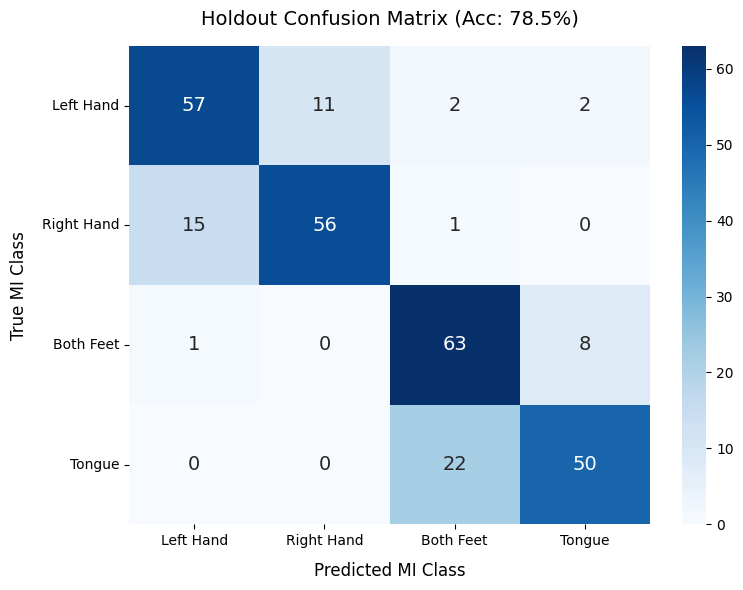

End of 5


In [9]:
lists.append(run_(1, parameters, batch_size, epochs, device, preprocessor, 0.01, 0.001))

## Subject 2


Processing Training Data...
Extracting GDF parameters from /kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A02T.gdf...
Setting channel info structure...
Could not determine channel type of the following channels, they will be set as EEG:
EEG-Fz, EEG, EEG, EEG, EEG, EEG, EEG, EEG-C3, EEG, EEG-Cz, EEG, EEG-C4, EEG, EEG, EEG, EEG, EEG, EEG, EEG, EEG-Pz, EEG, EEG, EOG-left, EOG-central, EOG-right
Creating raw.info structure...
Reading 0 ... 677168  =      0.000 ...  2708.672 secs...


/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '769', '770', '771', '772']
Epoch [10/300] | CE Loss: 0.0597 | WC Loss: 2.3370 | Ortho Loss: 0.0070 | Train Acc: 28.26%
Epoch [20/300] | CE Loss: 0.0621 | WC Loss: 2.6006 | Ortho Loss: 0.0037 | Train Acc: 30.35%
Epoch [30/300] | CE Loss: 0.0557 | WC Loss: 2.7234 | Ortho Loss: 0.0052 | Train Acc: 34.86%
Epoch [40/300] | CE Loss: 0.0540 | WC Loss: 2.7236 | Ortho Loss: 0.0093 | Train Acc: 43.54%
Epoch [50/300] | CE Loss: 0.0546 | WC Loss: 2.8693 | Ortho Loss: 0.0154 | Train Acc: 49.17%
Epoch [60/300] | CE Loss: 0.0512 | WC Loss: 2.8358 | Ortho Loss: 0.0189 | Train Acc: 52.71%
Epoch [70/300] | CE Loss: 0.0538 | WC Loss: 2.9192 | Ortho Loss: 0.0166 | Train Acc: 56.74%
Epoch [80/300] | CE Loss: 0.0496 | WC Loss: 2.9180 | Ortho Loss: 0.0155 | Train Acc: 57.78%
Epoch [90/300] | CE Loss: 0.0498 | WC Loss: 2.9894 | Ortho Loss: 0.0136 | Train Acc: 58.75%
Epoch [100/300] | CE Loss: 0.0455 | WC Loss: 2.9383 | Ortho Loss: 

/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '783']
Applying global training normalization to evaluation data...
Reconstructing trial indices from the relative timeline clock...
Labels successfully aligned! Verification Shape: (1440,)
Total unique trials reconstructed from timeline: 288/288

🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)
Target Subject File:  A02E.gdf
Total True Trials:    288
Final True Test Acc:  48.96%



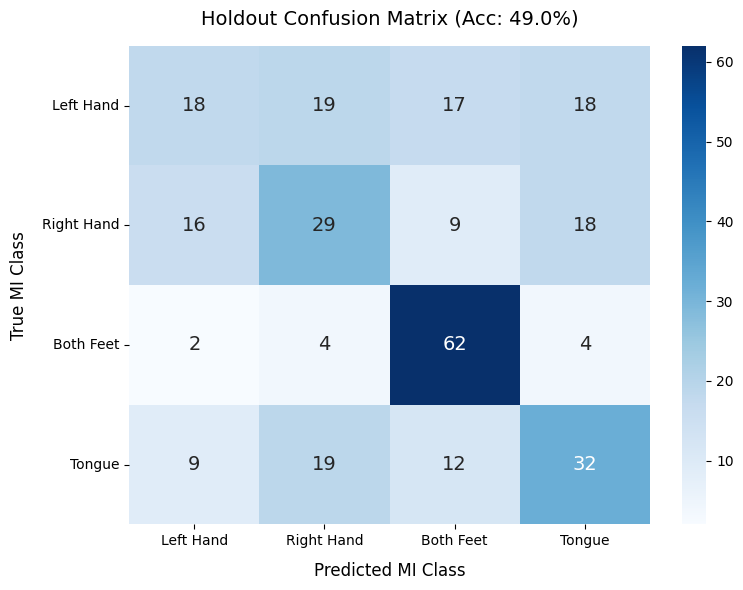

End of 1

Processing Training Data...
Extracting GDF parameters from /kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A02T.gdf...
Setting channel info structure...
Could not determine channel type of the following channels, they will be set as EEG:
EEG-Fz, EEG, EEG, EEG, EEG, EEG, EEG, EEG-C3, EEG, EEG-Cz, EEG, EEG-C4, EEG, EEG, EEG, EEG, EEG, EEG, EEG, EEG-Pz, EEG, EEG, EOG-left, EOG-central, EOG-right
Creating raw.info structure...
Reading 0 ... 677168  =      0.000 ...  2708.672 secs...


/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '769', '770', '771', '772']
Epoch [10/300] | CE Loss: 0.0630 | WC Loss: 3.3440 | Ortho Loss: 0.0192 | Train Acc: 30.14%
Epoch [20/300] | CE Loss: 0.0560 | WC Loss: 3.2857 | Ortho Loss: 0.0200 | Train Acc: 35.83%
Epoch [30/300] | CE Loss: 0.0545 | WC Loss: 3.0080 | Ortho Loss: 0.0279 | Train Acc: 47.29%
Epoch [40/300] | CE Loss: 0.0538 | WC Loss: 2.9645 | Ortho Loss: 0.0375 | Train Acc: 49.58%
Epoch [50/300] | CE Loss: 0.0497 | WC Loss: 3.1204 | Ortho Loss: 0.0442 | Train Acc: 52.50%
Epoch [60/300] | CE Loss: 0.0473 | WC Loss: 3.1102 | Ortho Loss: 0.0485 | Train Acc: 55.76%
Epoch [70/300] | CE Loss: 0.0488 | WC Loss: 3.2101 | Ortho Loss: 0.0516 | Train Acc: 55.62%
Epoch [80/300] | CE Loss: 0.0463 | WC Loss: 3.3121 | Ortho Loss: 0.0544 | Train Acc: 59.93%
Epoch [90/300] | CE Loss: 0.0427 | WC Loss: 3.3613 | Ortho Loss: 0.0546 | Train Acc: 58.96%
Epoch [100/300] | CE Loss: 0.0446 | WC Loss: 3.3929 | Ortho Loss: 

/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '783']
Applying global training normalization to evaluation data...
Reconstructing trial indices from the relative timeline clock...
Labels successfully aligned! Verification Shape: (1440,)
Total unique trials reconstructed from timeline: 288/288

🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)
Target Subject File:  A02E.gdf
Total True Trials:    288
Final True Test Acc:  49.65%



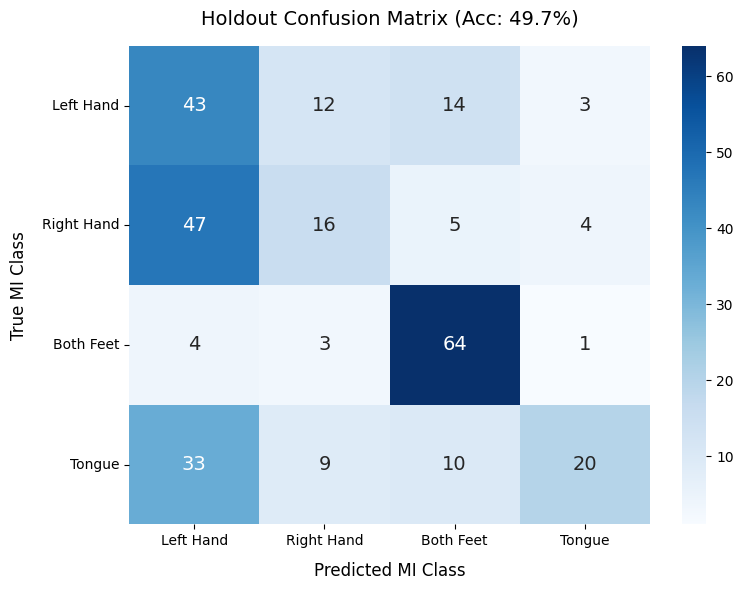

End of 2

Processing Training Data...
Extracting GDF parameters from /kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A02T.gdf...
Setting channel info structure...
Could not determine channel type of the following channels, they will be set as EEG:
EEG-Fz, EEG, EEG, EEG, EEG, EEG, EEG, EEG-C3, EEG, EEG-Cz, EEG, EEG-C4, EEG, EEG, EEG, EEG, EEG, EEG, EEG, EEG-Pz, EEG, EEG, EOG-left, EOG-central, EOG-right
Creating raw.info structure...
Reading 0 ... 677168  =      0.000 ...  2708.672 secs...


/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '769', '770', '771', '772']
Epoch [10/300] | CE Loss: 0.0627 | WC Loss: 3.3263 | Ortho Loss: 0.0027 | Train Acc: 28.12%
Epoch [20/300] | CE Loss: 0.0583 | WC Loss: 2.7850 | Ortho Loss: 0.0013 | Train Acc: 34.10%
Epoch [30/300] | CE Loss: 0.0594 | WC Loss: 2.7894 | Ortho Loss: 0.0100 | Train Acc: 40.90%
Epoch [40/300] | CE Loss: 0.0514 | WC Loss: 2.9759 | Ortho Loss: 0.0131 | Train Acc: 46.11%
Epoch [50/300] | CE Loss: 0.0522 | WC Loss: 2.8998 | Ortho Loss: 0.0204 | Train Acc: 52.36%
Epoch [60/300] | CE Loss: 0.0488 | WC Loss: 2.4942 | Ortho Loss: 0.0277 | Train Acc: 54.93%
Epoch [70/300] | CE Loss: 0.0523 | WC Loss: 2.5364 | Ortho Loss: 0.0348 | Train Acc: 54.65%
Epoch [80/300] | CE Loss: 0.0450 | WC Loss: 2.3980 | Ortho Loss: 0.0389 | Train Acc: 58.06%
Epoch [90/300] | CE Loss: 0.0547 | WC Loss: 2.4786 | Ortho Loss: 0.0412 | Train Acc: 58.19%
Epoch [100/300] | CE Loss: 0.0520 | WC Loss: 2.2647 | Ortho Loss: 

/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '783']
Applying global training normalization to evaluation data...
Reconstructing trial indices from the relative timeline clock...
Labels successfully aligned! Verification Shape: (1440,)
Total unique trials reconstructed from timeline: 288/288

🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)
Target Subject File:  A02E.gdf
Total True Trials:    288
Final True Test Acc:  46.18%



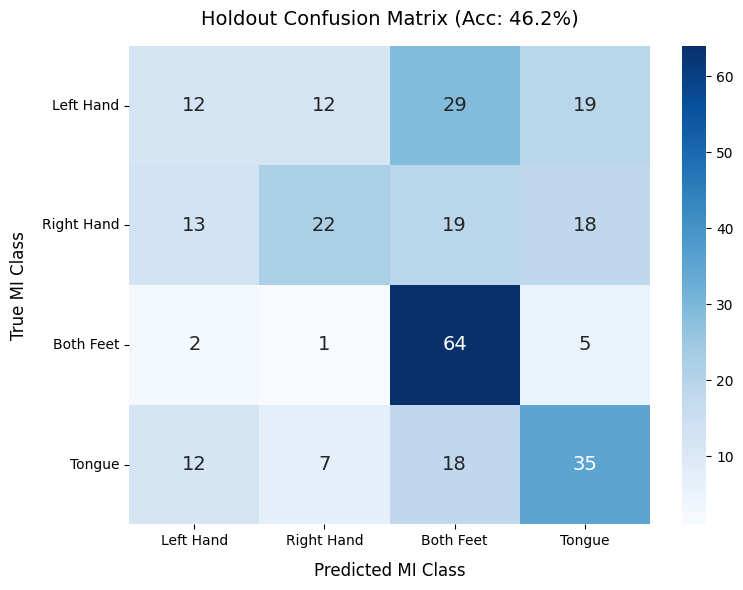

End of 3

Processing Training Data...
Extracting GDF parameters from /kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A02T.gdf...
Setting channel info structure...
Could not determine channel type of the following channels, they will be set as EEG:
EEG-Fz, EEG, EEG, EEG, EEG, EEG, EEG, EEG-C3, EEG, EEG-Cz, EEG, EEG-C4, EEG, EEG, EEG, EEG, EEG, EEG, EEG, EEG-Pz, EEG, EEG, EOG-left, EOG-central, EOG-right
Creating raw.info structure...
Reading 0 ... 677168  =      0.000 ...  2708.672 secs...


/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '769', '770', '771', '772']
Epoch [10/300] | CE Loss: 0.0613 | WC Loss: 3.1636 | Ortho Loss: 0.0047 | Train Acc: 29.86%
Epoch [20/300] | CE Loss: 0.0580 | WC Loss: 2.7103 | Ortho Loss: 0.0069 | Train Acc: 30.07%
Epoch [30/300] | CE Loss: 0.0581 | WC Loss: 2.6978 | Ortho Loss: 0.0128 | Train Acc: 40.14%
Epoch [40/300] | CE Loss: 0.0555 | WC Loss: 2.5877 | Ortho Loss: 0.0171 | Train Acc: 41.60%
Epoch [50/300] | CE Loss: 0.0496 | WC Loss: 2.4333 | Ortho Loss: 0.0202 | Train Acc: 49.58%
Epoch [60/300] | CE Loss: 0.0459 | WC Loss: 2.4739 | Ortho Loss: 0.0219 | Train Acc: 53.82%
Epoch [70/300] | CE Loss: 0.0450 | WC Loss: 2.5862 | Ortho Loss: 0.0219 | Train Acc: 57.50%
Epoch [80/300] | CE Loss: 0.0395 | WC Loss: 2.6900 | Ortho Loss: 0.0228 | Train Acc: 57.64%
Epoch [90/300] | CE Loss: 0.0465 | WC Loss: 2.7350 | Ortho Loss: 0.0226 | Train Acc: 60.35%
Epoch [100/300] | CE Loss: 0.0436 | WC Loss: 2.9092 | Ortho Loss: 

/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '783']
Applying global training normalization to evaluation data...
Reconstructing trial indices from the relative timeline clock...
Labels successfully aligned! Verification Shape: (1440,)
Total unique trials reconstructed from timeline: 288/288

🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)
Target Subject File:  A02E.gdf
Total True Trials:    288
Final True Test Acc:  51.39%



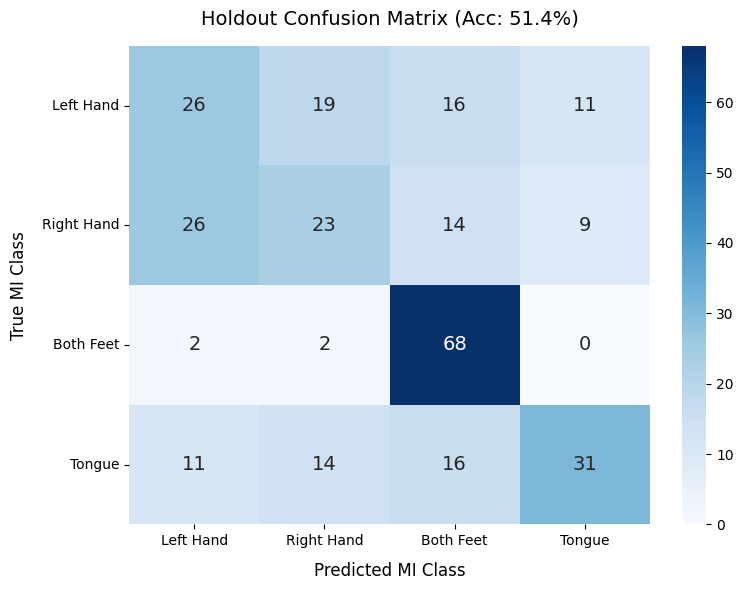

End of 4

Processing Training Data...
Extracting GDF parameters from /kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A02T.gdf...
Setting channel info structure...
Could not determine channel type of the following channels, they will be set as EEG:
EEG-Fz, EEG, EEG, EEG, EEG, EEG, EEG, EEG-C3, EEG, EEG-Cz, EEG, EEG-C4, EEG, EEG, EEG, EEG, EEG, EEG, EEG, EEG-Pz, EEG, EEG, EOG-left, EOG-central, EOG-right
Creating raw.info structure...
Reading 0 ... 677168  =      0.000 ...  2708.672 secs...


/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '769', '770', '771', '772']
Epoch [10/300] | CE Loss: 0.0618 | WC Loss: 1.8804 | Ortho Loss: 0.0071 | Train Acc: 25.62%
Epoch [20/300] | CE Loss: 0.0606 | WC Loss: 1.7654 | Ortho Loss: 0.0039 | Train Acc: 31.32%
Epoch [30/300] | CE Loss: 0.0586 | WC Loss: 1.7092 | Ortho Loss: 0.0055 | Train Acc: 40.14%
Epoch [40/300] | CE Loss: 0.0561 | WC Loss: 1.6812 | Ortho Loss: 0.0066 | Train Acc: 48.61%
Epoch [50/300] | CE Loss: 0.0538 | WC Loss: 1.6597 | Ortho Loss: 0.0081 | Train Acc: 55.49%
Epoch [60/300] | CE Loss: 0.0482 | WC Loss: 1.7481 | Ortho Loss: 0.0088 | Train Acc: 57.64%
Epoch [70/300] | CE Loss: 0.0577 | WC Loss: 1.8098 | Ortho Loss: 0.0100 | Train Acc: 60.42%
Epoch [80/300] | CE Loss: 0.0507 | WC Loss: 1.7987 | Ortho Loss: 0.0122 | Train Acc: 60.14%
Epoch [90/300] | CE Loss: 0.0441 | WC Loss: 1.8689 | Ortho Loss: 0.0128 | Train Acc: 60.49%
Epoch [100/300] | CE Loss: 0.0541 | WC Loss: 1.9253 | Ortho Loss: 

/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '783']
Applying global training normalization to evaluation data...
Reconstructing trial indices from the relative timeline clock...
Labels successfully aligned! Verification Shape: (1440,)
Total unique trials reconstructed from timeline: 288/288

🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)
Target Subject File:  A02E.gdf
Total True Trials:    288
Final True Test Acc:  52.78%



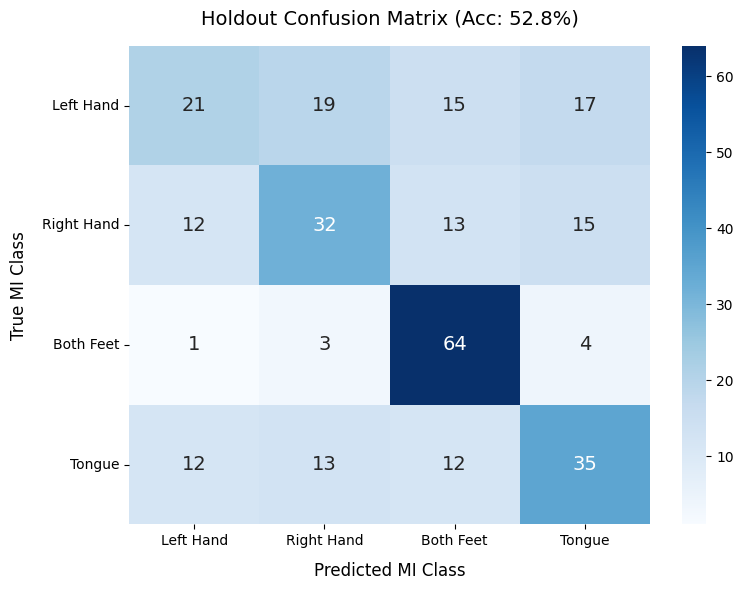

End of 5


In [10]:
lists.append(run_(2, parameters, batch_size, epochs, device, preprocessor, 0.01, 0.001))

## Subject 3


Processing Training Data...
Extracting GDF parameters from /kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A03T.gdf...
Setting channel info structure...
Could not determine channel type of the following channels, they will be set as EEG:
EEG-Fz, EEG, EEG, EEG, EEG, EEG, EEG, EEG-C3, EEG, EEG-Cz, EEG, EEG-C4, EEG, EEG, EEG, EEG, EEG, EEG, EEG, EEG-Pz, EEG, EEG, EOG-left, EOG-central, EOG-right
Creating raw.info structure...
Reading 0 ... 660529  =      0.000 ...  2642.116 secs...


/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '769', '770', '771', '772']
Epoch [10/300] | CE Loss: 0.0593 | WC Loss: 1.6412 | Ortho Loss: 0.0080 | Train Acc: 31.94%
Epoch [20/300] | CE Loss: 0.0530 | WC Loss: 1.5475 | Ortho Loss: 0.0039 | Train Acc: 47.36%
Epoch [30/300] | CE Loss: 0.0502 | WC Loss: 1.7649 | Ortho Loss: 0.0190 | Train Acc: 60.90%
Epoch [40/300] | CE Loss: 0.0478 | WC Loss: 1.9355 | Ortho Loss: 0.0391 | Train Acc: 66.32%
Epoch [50/300] | CE Loss: 0.0462 | WC Loss: 2.0625 | Ortho Loss: 0.0530 | Train Acc: 68.12%
Epoch [60/300] | CE Loss: 0.0407 | WC Loss: 2.2663 | Ortho Loss: 0.0612 | Train Acc: 71.53%
Epoch [70/300] | CE Loss: 0.0407 | WC Loss: 2.3417 | Ortho Loss: 0.0672 | Train Acc: 73.40%
Epoch [80/300] | CE Loss: 0.0411 | WC Loss: 2.5507 | Ortho Loss: 0.0711 | Train Acc: 74.44%
Epoch [90/300] | CE Loss: 0.0429 | WC Loss: 2.5730 | Ortho Loss: 0.0733 | Train Acc: 76.46%
Epoch [100/300] | CE Loss: 0.0374 | WC Loss: 2.5626 | Ortho Loss: 

/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '783']
Applying global training normalization to evaluation data...
Reconstructing trial indices from the relative timeline clock...
Labels successfully aligned! Verification Shape: (1440,)
Total unique trials reconstructed from timeline: 288/288

🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)
Target Subject File:  A03E.gdf
Total True Trials:    288
Final True Test Acc:  89.58%



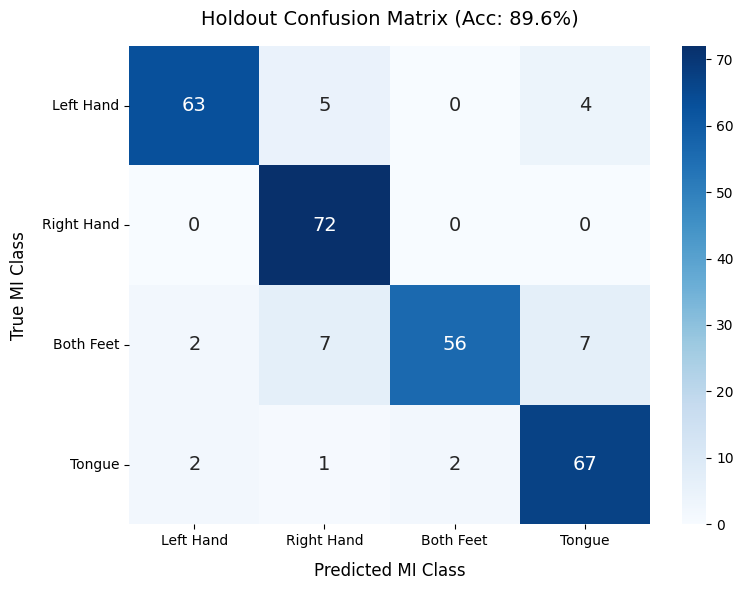

End of 1

Processing Training Data...
Extracting GDF parameters from /kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A03T.gdf...
Setting channel info structure...
Could not determine channel type of the following channels, they will be set as EEG:
EEG-Fz, EEG, EEG, EEG, EEG, EEG, EEG, EEG-C3, EEG, EEG-Cz, EEG, EEG-C4, EEG, EEG, EEG, EEG, EEG, EEG, EEG, EEG-Pz, EEG, EEG, EOG-left, EOG-central, EOG-right
Creating raw.info structure...
Reading 0 ... 660529  =      0.000 ...  2642.116 secs...


/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '769', '770', '771', '772']
Epoch [10/300] | CE Loss: 0.0576 | WC Loss: 2.4794 | Ortho Loss: 0.0256 | Train Acc: 37.78%
Epoch [20/300] | CE Loss: 0.0543 | WC Loss: 2.4474 | Ortho Loss: 0.0279 | Train Acc: 54.65%
Epoch [30/300] | CE Loss: 0.0454 | WC Loss: 2.5420 | Ortho Loss: 0.0369 | Train Acc: 66.67%
Epoch [40/300] | CE Loss: 0.0422 | WC Loss: 2.6674 | Ortho Loss: 0.0507 | Train Acc: 72.22%
Epoch [50/300] | CE Loss: 0.0370 | WC Loss: 2.7790 | Ortho Loss: 0.0593 | Train Acc: 77.64%
Epoch [60/300] | CE Loss: 0.0391 | WC Loss: 2.9314 | Ortho Loss: 0.0675 | Train Acc: 77.99%
Epoch [70/300] | CE Loss: 0.0355 | WC Loss: 2.9394 | Ortho Loss: 0.0749 | Train Acc: 80.76%
Epoch [80/300] | CE Loss: 0.0349 | WC Loss: 2.9454 | Ortho Loss: 0.0795 | Train Acc: 81.32%
Epoch [90/300] | CE Loss: 0.0385 | WC Loss: 3.0705 | Ortho Loss: 0.0846 | Train Acc: 80.21%
Epoch [100/300] | CE Loss: 0.0308 | WC Loss: 3.1029 | Ortho Loss: 

/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '783']
Applying global training normalization to evaluation data...
Reconstructing trial indices from the relative timeline clock...
Labels successfully aligned! Verification Shape: (1440,)
Total unique trials reconstructed from timeline: 288/288

🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)
Target Subject File:  A03E.gdf
Total True Trials:    288
Final True Test Acc:  90.62%



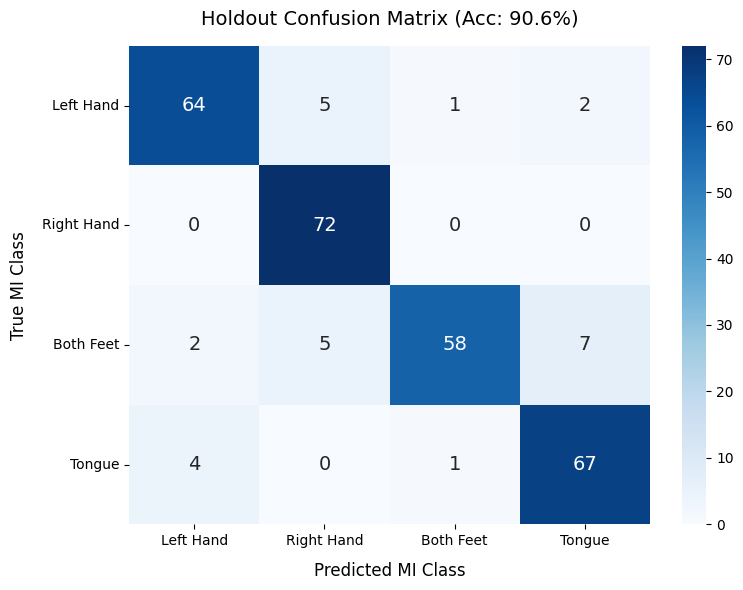

End of 2

Processing Training Data...
Extracting GDF parameters from /kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A03T.gdf...
Setting channel info structure...
Could not determine channel type of the following channels, they will be set as EEG:
EEG-Fz, EEG, EEG, EEG, EEG, EEG, EEG, EEG-C3, EEG, EEG-Cz, EEG, EEG-C4, EEG, EEG, EEG, EEG, EEG, EEG, EEG, EEG-Pz, EEG, EEG, EOG-left, EOG-central, EOG-right
Creating raw.info structure...
Reading 0 ... 660529  =      0.000 ...  2642.116 secs...


/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '769', '770', '771', '772']
Epoch [10/300] | CE Loss: 0.0577 | WC Loss: 1.6211 | Ortho Loss: 0.0273 | Train Acc: 38.61%
Epoch [20/300] | CE Loss: 0.0491 | WC Loss: 1.6916 | Ortho Loss: 0.0232 | Train Acc: 53.40%
Epoch [30/300] | CE Loss: 0.0482 | WC Loss: 1.9094 | Ortho Loss: 0.0115 | Train Acc: 64.10%
Epoch [40/300] | CE Loss: 0.0372 | WC Loss: 2.1047 | Ortho Loss: 0.0086 | Train Acc: 70.69%
Epoch [50/300] | CE Loss: 0.0355 | WC Loss: 2.3031 | Ortho Loss: 0.0091 | Train Acc: 75.42%
Epoch [60/300] | CE Loss: 0.0337 | WC Loss: 2.4827 | Ortho Loss: 0.0086 | Train Acc: 77.01%
Epoch [70/300] | CE Loss: 0.0347 | WC Loss: 2.6327 | Ortho Loss: 0.0089 | Train Acc: 77.57%
Epoch [80/300] | CE Loss: 0.0375 | WC Loss: 2.8112 | Ortho Loss: 0.0087 | Train Acc: 78.82%
Epoch [90/300] | CE Loss: 0.0394 | WC Loss: 2.8350 | Ortho Loss: 0.0097 | Train Acc: 77.57%
Epoch [100/300] | CE Loss: 0.0331 | WC Loss: 2.9345 | Ortho Loss: 

/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '783']
Applying global training normalization to evaluation data...
Reconstructing trial indices from the relative timeline clock...
Labels successfully aligned! Verification Shape: (1440,)
Total unique trials reconstructed from timeline: 288/288

🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)
Target Subject File:  A03E.gdf
Total True Trials:    288
Final True Test Acc:  86.11%



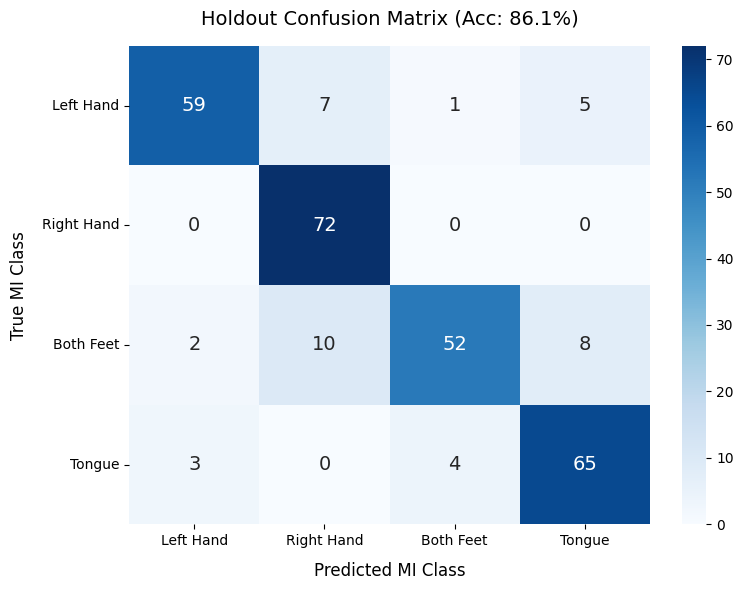

End of 3

Processing Training Data...
Extracting GDF parameters from /kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A03T.gdf...
Setting channel info structure...
Could not determine channel type of the following channels, they will be set as EEG:
EEG-Fz, EEG, EEG, EEG, EEG, EEG, EEG, EEG-C3, EEG, EEG-Cz, EEG, EEG-C4, EEG, EEG, EEG, EEG, EEG, EEG, EEG, EEG-Pz, EEG, EEG, EOG-left, EOG-central, EOG-right
Creating raw.info structure...
Reading 0 ... 660529  =      0.000 ...  2642.116 secs...


/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '769', '770', '771', '772']
Epoch [10/300] | CE Loss: 0.0546 | WC Loss: 1.5307 | Ortho Loss: 0.0052 | Train Acc: 36.32%
Epoch [20/300] | CE Loss: 0.0512 | WC Loss: 2.1502 | Ortho Loss: 0.0036 | Train Acc: 48.19%
Epoch [30/300] | CE Loss: 0.0509 | WC Loss: 2.0879 | Ortho Loss: 0.0076 | Train Acc: 59.51%
Epoch [40/300] | CE Loss: 0.0426 | WC Loss: 2.2230 | Ortho Loss: 0.0100 | Train Acc: 67.22%
Epoch [50/300] | CE Loss: 0.0429 | WC Loss: 2.2903 | Ortho Loss: 0.0110 | Train Acc: 70.76%
Epoch [60/300] | CE Loss: 0.0398 | WC Loss: 2.3578 | Ortho Loss: 0.0114 | Train Acc: 73.82%
Epoch [70/300] | CE Loss: 0.0387 | WC Loss: 2.4765 | Ortho Loss: 0.0125 | Train Acc: 74.72%
Epoch [80/300] | CE Loss: 0.0363 | WC Loss: 2.5071 | Ortho Loss: 0.0135 | Train Acc: 76.32%
Epoch [90/300] | CE Loss: 0.0345 | WC Loss: 2.5116 | Ortho Loss: 0.0144 | Train Acc: 77.71%
Epoch [100/300] | CE Loss: 0.0398 | WC Loss: 2.5542 | Ortho Loss: 

/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '783']
Applying global training normalization to evaluation data...
Reconstructing trial indices from the relative timeline clock...
Labels successfully aligned! Verification Shape: (1440,)
Total unique trials reconstructed from timeline: 288/288

🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)
Target Subject File:  A03E.gdf
Total True Trials:    288
Final True Test Acc:  86.46%



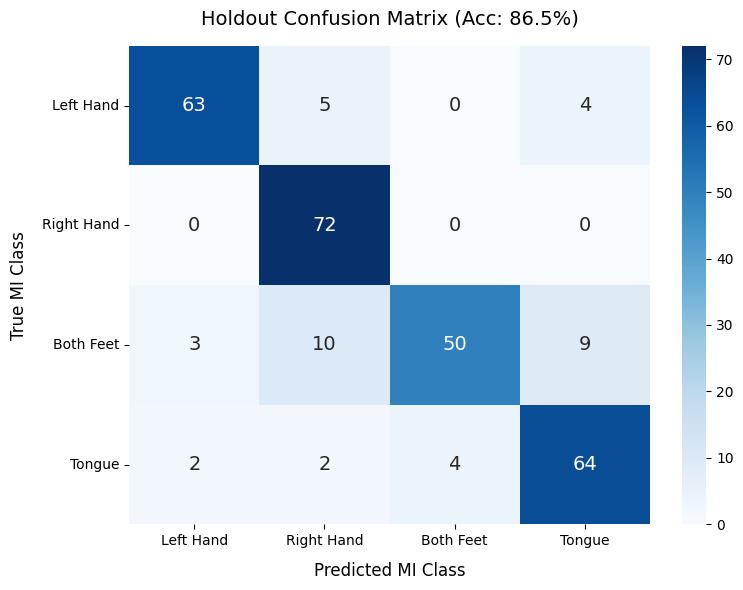

End of 4

Processing Training Data...
Extracting GDF parameters from /kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A03T.gdf...
Setting channel info structure...
Could not determine channel type of the following channels, they will be set as EEG:
EEG-Fz, EEG, EEG, EEG, EEG, EEG, EEG, EEG-C3, EEG, EEG-Cz, EEG, EEG-C4, EEG, EEG, EEG, EEG, EEG, EEG, EEG, EEG-Pz, EEG, EEG, EOG-left, EOG-central, EOG-right
Creating raw.info structure...
Reading 0 ... 660529  =      0.000 ...  2642.116 secs...


/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '769', '770', '771', '772']
Epoch [10/300] | CE Loss: 0.0642 | WC Loss: 1.8598 | Ortho Loss: 0.0043 | Train Acc: 31.74%
Epoch [20/300] | CE Loss: 0.0542 | WC Loss: 1.5995 | Ortho Loss: 0.0209 | Train Acc: 45.21%
Epoch [30/300] | CE Loss: 0.0430 | WC Loss: 1.6767 | Ortho Loss: 0.0290 | Train Acc: 59.79%
Epoch [40/300] | CE Loss: 0.0432 | WC Loss: 1.8168 | Ortho Loss: 0.0300 | Train Acc: 64.51%
Epoch [50/300] | CE Loss: 0.0418 | WC Loss: 2.0611 | Ortho Loss: 0.0263 | Train Acc: 69.17%
Epoch [60/300] | CE Loss: 0.0419 | WC Loss: 2.2184 | Ortho Loss: 0.0246 | Train Acc: 69.10%
Epoch [70/300] | CE Loss: 0.0398 | WC Loss: 2.3784 | Ortho Loss: 0.0224 | Train Acc: 70.76%
Epoch [80/300] | CE Loss: 0.0415 | WC Loss: 2.3737 | Ortho Loss: 0.0205 | Train Acc: 71.60%
Epoch [90/300] | CE Loss: 0.0389 | WC Loss: 2.4854 | Ortho Loss: 0.0188 | Train Acc: 70.97%
Epoch [100/300] | CE Loss: 0.0338 | WC Loss: 2.6612 | Ortho Loss: 

/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '783']
Applying global training normalization to evaluation data...
Reconstructing trial indices from the relative timeline clock...
Labels successfully aligned! Verification Shape: (1440,)
Total unique trials reconstructed from timeline: 288/288

🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)
Target Subject File:  A03E.gdf
Total True Trials:    288
Final True Test Acc:  82.99%



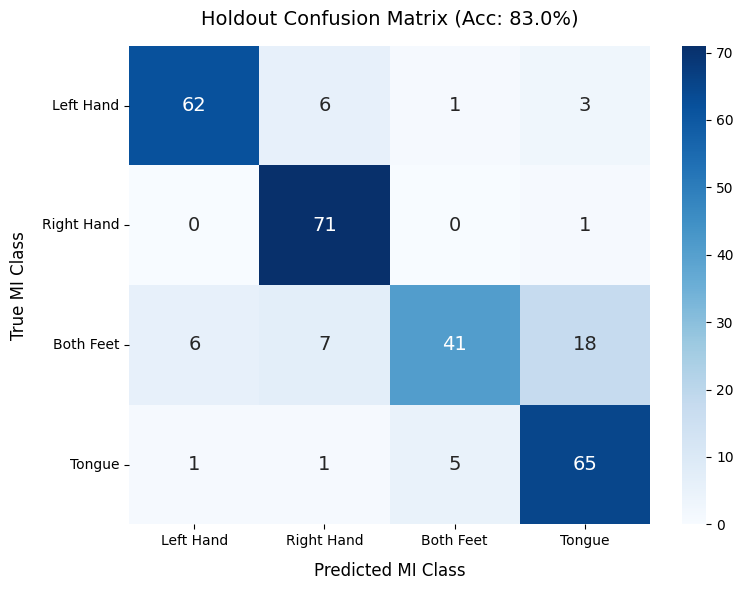

End of 5


In [11]:
lists.append(run_(3, parameters, batch_size, epochs, device, preprocessor, 0.01, 0.001))

## Subject 4


Processing Training Data...
Extracting GDF parameters from /kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A04T.gdf...
Setting channel info structure...
Could not determine channel type of the following channels, they will be set as EEG:
EEG-Fz, EEG, EEG, EEG, EEG, EEG, EEG, EEG-C3, EEG, EEG-Cz, EEG, EEG-C4, EEG, EEG, EEG, EEG, EEG, EEG, EEG, EEG-Pz, EEG, EEG, EOG-left, EOG-central, EOG-right
Creating raw.info structure...
Reading 0 ... 600914  =      0.000 ...  2403.656 secs...


/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '32766', '768', '769', '770', '771', '772']
Epoch [10/300] | CE Loss: 0.0574 | WC Loss: 1.5926 | Ortho Loss: 0.0199 | Train Acc: 33.89%
Epoch [20/300] | CE Loss: 0.0619 | WC Loss: 1.5854 | Ortho Loss: 0.0094 | Train Acc: 35.90%
Epoch [30/300] | CE Loss: 0.0568 | WC Loss: 1.6811 | Ortho Loss: 0.0103 | Train Acc: 41.39%
Epoch [40/300] | CE Loss: 0.0525 | WC Loss: 1.7468 | Ortho Loss: 0.0120 | Train Acc: 47.92%
Epoch [50/300] | CE Loss: 0.0551 | WC Loss: 1.8735 | Ortho Loss: 0.0133 | Train Acc: 50.42%
Epoch [60/300] | CE Loss: 0.0489 | WC Loss: 1.9015 | Ortho Loss: 0.0122 | Train Acc: 53.61%
Epoch [70/300] | CE Loss: 0.0555 | WC Loss: 1.9541 | Ortho Loss: 0.0121 | Train Acc: 54.86%
Epoch [80/300] | CE Loss: 0.0545 | WC Loss: 2.0280 | Ortho Loss: 0.0109 | Train Acc: 56.25%
Epoch [90/300] | CE Loss: 0.0531 | WC Loss: 2.0117 | Ortho Loss: 0.0101 | Train Acc: 56.88%
Epoch [100/300] | CE Loss: 0.0480 | WC Loss: 2.0651 | Ortho Loss: 0.0100 | Train

/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '783']
Applying global training normalization to evaluation data...
Reconstructing trial indices from the relative timeline clock...
Labels successfully aligned! Verification Shape: (1440,)
Total unique trials reconstructed from timeline: 288/288

🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)
Target Subject File:  A04E.gdf
Total True Trials:    288
Final True Test Acc:  56.25%



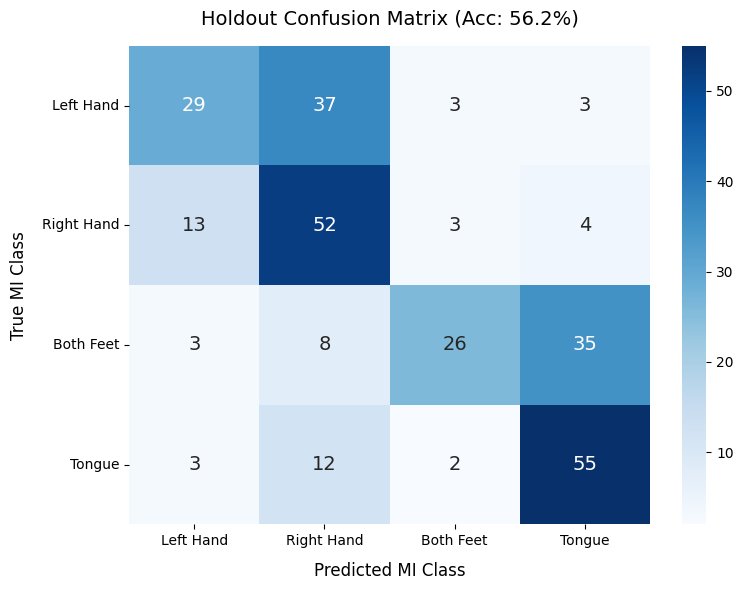

End of 1

Processing Training Data...
Extracting GDF parameters from /kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A04T.gdf...
Setting channel info structure...
Could not determine channel type of the following channels, they will be set as EEG:
EEG-Fz, EEG, EEG, EEG, EEG, EEG, EEG, EEG-C3, EEG, EEG-Cz, EEG, EEG-C4, EEG, EEG, EEG, EEG, EEG, EEG, EEG, EEG-Pz, EEG, EEG, EOG-left, EOG-central, EOG-right
Creating raw.info structure...
Reading 0 ... 600914  =      0.000 ...  2403.656 secs...


/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '32766', '768', '769', '770', '771', '772']
Epoch [10/300] | CE Loss: 0.0604 | WC Loss: 1.2931 | Ortho Loss: 0.0099 | Train Acc: 28.68%
Epoch [20/300] | CE Loss: 0.0585 | WC Loss: 1.0629 | Ortho Loss: 0.0098 | Train Acc: 35.07%
Epoch [30/300] | CE Loss: 0.0572 | WC Loss: 1.1635 | Ortho Loss: 0.0084 | Train Acc: 40.76%
Epoch [40/300] | CE Loss: 0.0530 | WC Loss: 1.2652 | Ortho Loss: 0.0084 | Train Acc: 47.85%
Epoch [50/300] | CE Loss: 0.0539 | WC Loss: 1.2370 | Ortho Loss: 0.0098 | Train Acc: 51.67%
Epoch [60/300] | CE Loss: 0.0521 | WC Loss: 1.3053 | Ortho Loss: 0.0123 | Train Acc: 54.65%
Epoch [70/300] | CE Loss: 0.0503 | WC Loss: 1.3736 | Ortho Loss: 0.0137 | Train Acc: 54.79%
Epoch [80/300] | CE Loss: 0.0482 | WC Loss: 1.4175 | Ortho Loss: 0.0154 | Train Acc: 58.61%
Epoch [90/300] | CE Loss: 0.0463 | WC Loss: 1.4349 | Ortho Loss: 0.0176 | Train Acc: 59.44%
Epoch [100/300] | CE Loss: 0.0468 | WC Loss: 1.4446 | Ortho Loss: 0.0195 | Train

/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '783']
Applying global training normalization to evaluation data...
Reconstructing trial indices from the relative timeline clock...
Labels successfully aligned! Verification Shape: (1440,)
Total unique trials reconstructed from timeline: 288/288

🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)
Target Subject File:  A04E.gdf
Total True Trials:    288
Final True Test Acc:  60.07%



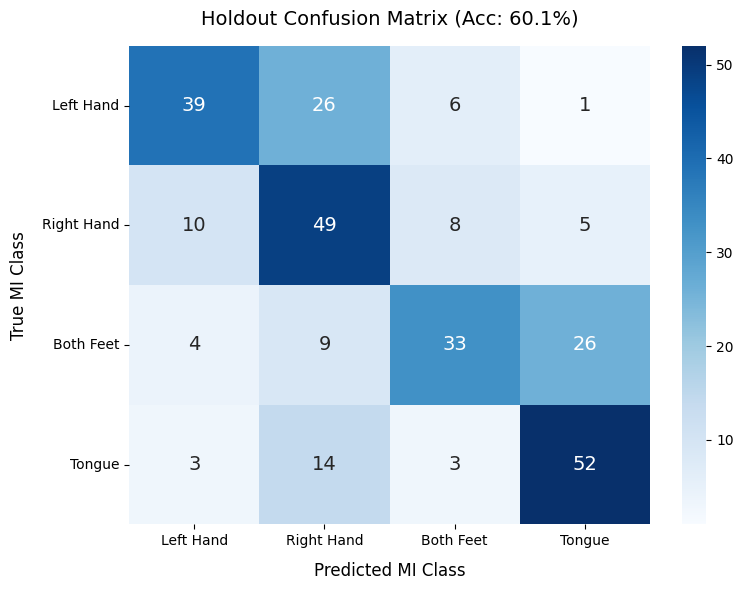

End of 2

Processing Training Data...
Extracting GDF parameters from /kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A04T.gdf...
Setting channel info structure...
Could not determine channel type of the following channels, they will be set as EEG:
EEG-Fz, EEG, EEG, EEG, EEG, EEG, EEG, EEG-C3, EEG, EEG-Cz, EEG, EEG-C4, EEG, EEG, EEG, EEG, EEG, EEG, EEG, EEG-Pz, EEG, EEG, EOG-left, EOG-central, EOG-right
Creating raw.info structure...
Reading 0 ... 600914  =      0.000 ...  2403.656 secs...


/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '32766', '768', '769', '770', '771', '772']
Epoch [10/300] | CE Loss: 0.0587 | WC Loss: 1.3263 | Ortho Loss: 0.0039 | Train Acc: 32.50%
Epoch [20/300] | CE Loss: 0.0590 | WC Loss: 1.3936 | Ortho Loss: 0.0078 | Train Acc: 32.71%
Epoch [30/300] | CE Loss: 0.0532 | WC Loss: 1.3190 | Ortho Loss: 0.0057 | Train Acc: 41.18%
Epoch [40/300] | CE Loss: 0.0532 | WC Loss: 1.4023 | Ortho Loss: 0.0084 | Train Acc: 45.56%
Epoch [50/300] | CE Loss: 0.0506 | WC Loss: 1.4098 | Ortho Loss: 0.0109 | Train Acc: 49.17%
Epoch [60/300] | CE Loss: 0.0512 | WC Loss: 1.4423 | Ortho Loss: 0.0149 | Train Acc: 52.85%
Epoch [70/300] | CE Loss: 0.0549 | WC Loss: 1.4497 | Ortho Loss: 0.0188 | Train Acc: 56.74%
Epoch [80/300] | CE Loss: 0.0547 | WC Loss: 1.4761 | Ortho Loss: 0.0218 | Train Acc: 54.65%
Epoch [90/300] | CE Loss: 0.0502 | WC Loss: 1.5005 | Ortho Loss: 0.0256 | Train Acc: 56.81%
Epoch [100/300] | CE Loss: 0.0468 | WC Loss: 1.5556 | Ortho Loss: 0.0281 | Train

/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '783']
Applying global training normalization to evaluation data...
Reconstructing trial indices from the relative timeline clock...
Labels successfully aligned! Verification Shape: (1440,)
Total unique trials reconstructed from timeline: 288/288

🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)
Target Subject File:  A04E.gdf
Total True Trials:    288
Final True Test Acc:  63.89%



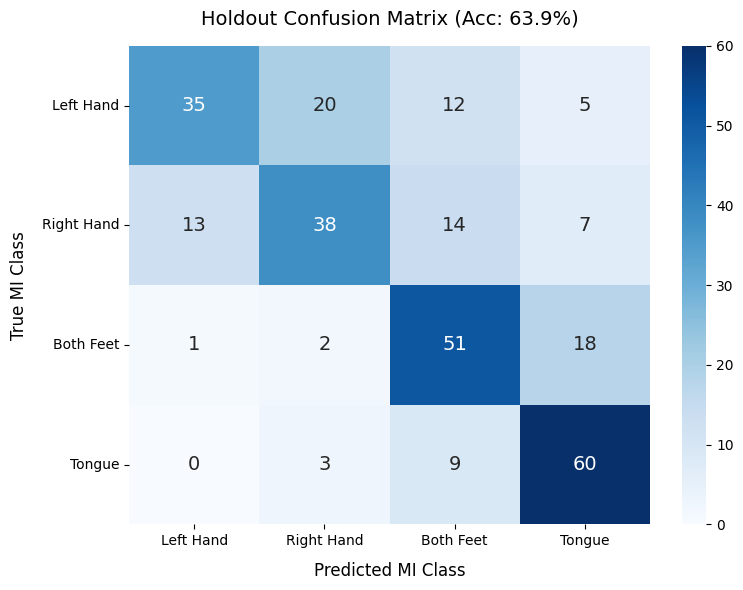

End of 3

Processing Training Data...
Extracting GDF parameters from /kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A04T.gdf...
Setting channel info structure...
Could not determine channel type of the following channels, they will be set as EEG:
EEG-Fz, EEG, EEG, EEG, EEG, EEG, EEG, EEG-C3, EEG, EEG-Cz, EEG, EEG-C4, EEG, EEG, EEG, EEG, EEG, EEG, EEG, EEG-Pz, EEG, EEG, EOG-left, EOG-central, EOG-right
Creating raw.info structure...
Reading 0 ... 600914  =      0.000 ...  2403.656 secs...


/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '32766', '768', '769', '770', '771', '772']
Epoch [10/300] | CE Loss: 0.0628 | WC Loss: 1.6124 | Ortho Loss: 0.0085 | Train Acc: 29.17%
Epoch [20/300] | CE Loss: 0.0593 | WC Loss: 1.5783 | Ortho Loss: 0.0067 | Train Acc: 31.94%
Epoch [30/300] | CE Loss: 0.0611 | WC Loss: 1.6439 | Ortho Loss: 0.0079 | Train Acc: 36.32%
Epoch [40/300] | CE Loss: 0.0550 | WC Loss: 1.7183 | Ortho Loss: 0.0090 | Train Acc: 40.62%
Epoch [50/300] | CE Loss: 0.0547 | WC Loss: 1.7647 | Ortho Loss: 0.0086 | Train Acc: 46.32%
Epoch [60/300] | CE Loss: 0.0563 | WC Loss: 1.8527 | Ortho Loss: 0.0092 | Train Acc: 47.57%
Epoch [70/300] | CE Loss: 0.0564 | WC Loss: 1.8797 | Ortho Loss: 0.0097 | Train Acc: 52.01%
Epoch [80/300] | CE Loss: 0.0538 | WC Loss: 1.9034 | Ortho Loss: 0.0080 | Train Acc: 54.17%
Epoch [90/300] | CE Loss: 0.0475 | WC Loss: 1.9589 | Ortho Loss: 0.0066 | Train Acc: 55.00%
Epoch [100/300] | CE Loss: 0.0479 | WC Loss: 1.9845 | Ortho Loss: 0.0071 | Train

/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '783']
Applying global training normalization to evaluation data...
Reconstructing trial indices from the relative timeline clock...
Labels successfully aligned! Verification Shape: (1440,)
Total unique trials reconstructed from timeline: 288/288

🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)
Target Subject File:  A04E.gdf
Total True Trials:    288
Final True Test Acc:  56.25%



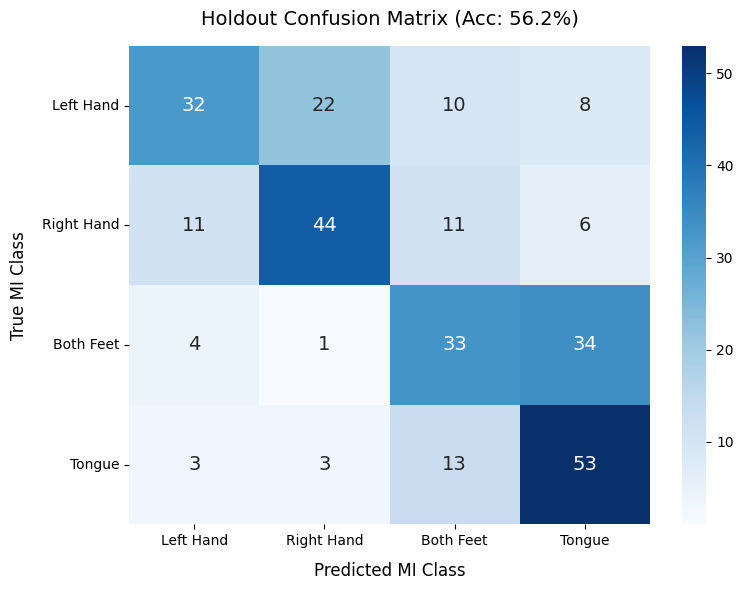

End of 4

Processing Training Data...
Extracting GDF parameters from /kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A04T.gdf...
Setting channel info structure...
Could not determine channel type of the following channels, they will be set as EEG:
EEG-Fz, EEG, EEG, EEG, EEG, EEG, EEG, EEG-C3, EEG, EEG-Cz, EEG, EEG-C4, EEG, EEG, EEG, EEG, EEG, EEG, EEG, EEG-Pz, EEG, EEG, EOG-left, EOG-central, EOG-right
Creating raw.info structure...
Reading 0 ... 600914  =      0.000 ...  2403.656 secs...


/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '32766', '768', '769', '770', '771', '772']
Epoch [10/300] | CE Loss: 0.0608 | WC Loss: 1.7394 | Ortho Loss: 0.0028 | Train Acc: 26.46%
Epoch [20/300] | CE Loss: 0.0576 | WC Loss: 1.4513 | Ortho Loss: 0.0050 | Train Acc: 31.60%
Epoch [30/300] | CE Loss: 0.0549 | WC Loss: 1.5880 | Ortho Loss: 0.0046 | Train Acc: 37.22%
Epoch [40/300] | CE Loss: 0.0573 | WC Loss: 1.7116 | Ortho Loss: 0.0043 | Train Acc: 44.72%
Epoch [50/300] | CE Loss: 0.0502 | WC Loss: 1.8251 | Ortho Loss: 0.0054 | Train Acc: 48.82%
Epoch [60/300] | CE Loss: 0.0494 | WC Loss: 1.9064 | Ortho Loss: 0.0058 | Train Acc: 53.47%
Epoch [70/300] | CE Loss: 0.0536 | WC Loss: 1.9132 | Ortho Loss: 0.0073 | Train Acc: 53.68%
Epoch [80/300] | CE Loss: 0.0484 | WC Loss: 1.9819 | Ortho Loss: 0.0092 | Train Acc: 53.75%
Epoch [90/300] | CE Loss: 0.0503 | WC Loss: 2.0753 | Ortho Loss: 0.0106 | Train Acc: 57.22%
Epoch [100/300] | CE Loss: 0.0499 | WC Loss: 2.0679 | Ortho Loss: 0.0114 | Train

/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '783']
Applying global training normalization to evaluation data...
Reconstructing trial indices from the relative timeline clock...
Labels successfully aligned! Verification Shape: (1440,)
Total unique trials reconstructed from timeline: 288/288

🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)
Target Subject File:  A04E.gdf
Total True Trials:    288
Final True Test Acc:  61.46%



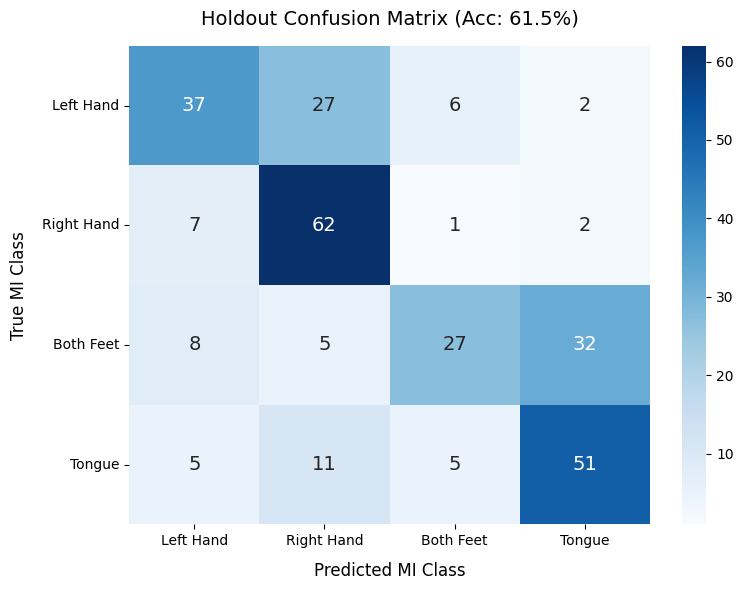

End of 5


In [12]:
lists.append(run_(4, parameters, batch_size, epochs, device, preprocessor, 0.01, 0.001))

## Subject 5


Processing Training Data...
Extracting GDF parameters from /kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A05T.gdf...
Setting channel info structure...
Could not determine channel type of the following channels, they will be set as EEG:
EEG-Fz, EEG, EEG, EEG, EEG, EEG, EEG, EEG-C3, EEG, EEG-Cz, EEG, EEG-C4, EEG, EEG, EEG, EEG, EEG, EEG, EEG, EEG-Pz, EEG, EEG, EOG-left, EOG-central, EOG-right
Creating raw.info structure...
Reading 0 ... 686119  =      0.000 ...  2744.476 secs...


/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '769', '770', '771', '772']
Epoch [10/300] | CE Loss: 0.0639 | WC Loss: 2.0361 | Ortho Loss: 0.0136 | Train Acc: 28.89%
Epoch [20/300] | CE Loss: 0.0591 | WC Loss: 1.4294 | Ortho Loss: 0.0173 | Train Acc: 30.49%
Epoch [30/300] | CE Loss: 0.0547 | WC Loss: 1.3588 | Ortho Loss: 0.0238 | Train Acc: 39.93%
Epoch [40/300] | CE Loss: 0.0521 | WC Loss: 1.1668 | Ortho Loss: 0.0391 | Train Acc: 45.83%
Epoch [50/300] | CE Loss: 0.0532 | WC Loss: 1.1138 | Ortho Loss: 0.0574 | Train Acc: 50.83%
Epoch [60/300] | CE Loss: 0.0517 | WC Loss: 1.0807 | Ortho Loss: 0.0713 | Train Acc: 54.38%
Epoch [70/300] | CE Loss: 0.0448 | WC Loss: 1.2558 | Ortho Loss: 0.0796 | Train Acc: 59.72%
Epoch [80/300] | CE Loss: 0.0475 | WC Loss: 1.3500 | Ortho Loss: 0.0873 | Train Acc: 58.89%
Epoch [90/300] | CE Loss: 0.0493 | WC Loss: 1.5759 | Ortho Loss: 0.0935 | Train Acc: 61.46%
Epoch [100/300] | CE Loss: 0.0455 | WC Loss: 1.5122 | Ortho Loss: 

/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '783']
Applying global training normalization to evaluation data...
Reconstructing trial indices from the relative timeline clock...
Labels successfully aligned! Verification Shape: (1440,)
Total unique trials reconstructed from timeline: 288/288

🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)
Target Subject File:  A05E.gdf
Total True Trials:    288
Final True Test Acc:  51.04%



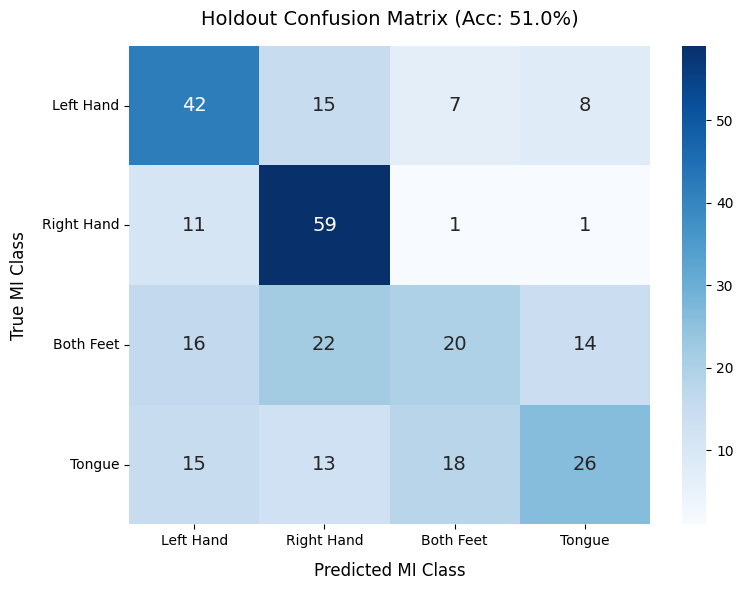

End of 1

Processing Training Data...
Extracting GDF parameters from /kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A05T.gdf...
Setting channel info structure...
Could not determine channel type of the following channels, they will be set as EEG:
EEG-Fz, EEG, EEG, EEG, EEG, EEG, EEG, EEG-C3, EEG, EEG-Cz, EEG, EEG-C4, EEG, EEG, EEG, EEG, EEG, EEG, EEG, EEG-Pz, EEG, EEG, EOG-left, EOG-central, EOG-right
Creating raw.info structure...
Reading 0 ... 686119  =      0.000 ...  2744.476 secs...


/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '769', '770', '771', '772']
Epoch [10/300] | CE Loss: 0.0609 | WC Loss: 2.9968 | Ortho Loss: 0.0026 | Train Acc: 30.90%
Epoch [20/300] | CE Loss: 0.0607 | WC Loss: 2.4841 | Ortho Loss: 0.0119 | Train Acc: 32.22%
Epoch [30/300] | CE Loss: 0.0590 | WC Loss: 2.3485 | Ortho Loss: 0.0216 | Train Acc: 39.44%
Epoch [40/300] | CE Loss: 0.0549 | WC Loss: 2.4215 | Ortho Loss: 0.0248 | Train Acc: 43.75%
Epoch [50/300] | CE Loss: 0.0498 | WC Loss: 2.6305 | Ortho Loss: 0.0242 | Train Acc: 50.35%
Epoch [60/300] | CE Loss: 0.0512 | WC Loss: 2.9282 | Ortho Loss: 0.0235 | Train Acc: 55.28%
Epoch [70/300] | CE Loss: 0.0493 | WC Loss: 3.1839 | Ortho Loss: 0.0232 | Train Acc: 55.83%
Epoch [80/300] | CE Loss: 0.0499 | WC Loss: 3.2228 | Ortho Loss: 0.0223 | Train Acc: 59.17%
Epoch [90/300] | CE Loss: 0.0463 | WC Loss: 3.4142 | Ortho Loss: 0.0224 | Train Acc: 57.50%
Epoch [100/300] | CE Loss: 0.0404 | WC Loss: 3.4305 | Ortho Loss: 

/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '783']
Applying global training normalization to evaluation data...
Reconstructing trial indices from the relative timeline clock...
Labels successfully aligned! Verification Shape: (1440,)
Total unique trials reconstructed from timeline: 288/288

🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)
Target Subject File:  A05E.gdf
Total True Trials:    288
Final True Test Acc:  51.39%



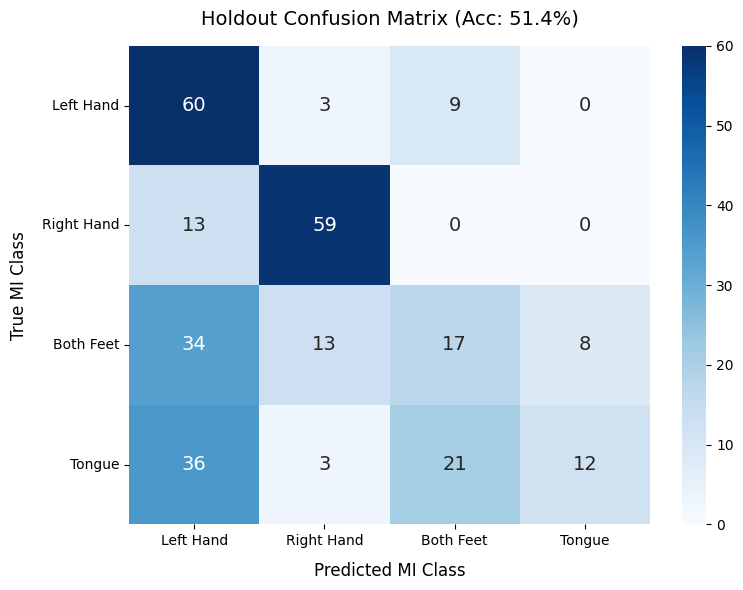

End of 2

Processing Training Data...
Extracting GDF parameters from /kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A05T.gdf...
Setting channel info structure...
Could not determine channel type of the following channels, they will be set as EEG:
EEG-Fz, EEG, EEG, EEG, EEG, EEG, EEG, EEG-C3, EEG, EEG-Cz, EEG, EEG-C4, EEG, EEG, EEG, EEG, EEG, EEG, EEG, EEG-Pz, EEG, EEG, EOG-left, EOG-central, EOG-right
Creating raw.info structure...
Reading 0 ... 686119  =      0.000 ...  2744.476 secs...


/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '769', '770', '771', '772']
Epoch [10/300] | CE Loss: 0.0609 | WC Loss: 3.1513 | Ortho Loss: 0.0072 | Train Acc: 26.60%
Epoch [20/300] | CE Loss: 0.0619 | WC Loss: 3.9631 | Ortho Loss: 0.0052 | Train Acc: 28.40%
Epoch [30/300] | CE Loss: 0.0575 | WC Loss: 3.5433 | Ortho Loss: 0.0056 | Train Acc: 36.67%
Epoch [40/300] | CE Loss: 0.0535 | WC Loss: 3.6054 | Ortho Loss: 0.0127 | Train Acc: 43.96%
Epoch [50/300] | CE Loss: 0.0556 | WC Loss: 3.7876 | Ortho Loss: 0.0136 | Train Acc: 49.51%
Epoch [60/300] | CE Loss: 0.0531 | WC Loss: 3.8530 | Ortho Loss: 0.0149 | Train Acc: 52.57%
Epoch [70/300] | CE Loss: 0.0478 | WC Loss: 3.8351 | Ortho Loss: 0.0147 | Train Acc: 55.97%
Epoch [80/300] | CE Loss: 0.0489 | WC Loss: 4.0027 | Ortho Loss: 0.0144 | Train Acc: 59.51%
Epoch [90/300] | CE Loss: 0.0473 | WC Loss: 3.9887 | Ortho Loss: 0.0156 | Train Acc: 60.56%
Epoch [100/300] | CE Loss: 0.0439 | WC Loss: 4.0224 | Ortho Loss: 

/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '783']
Applying global training normalization to evaluation data...
Reconstructing trial indices from the relative timeline clock...
Labels successfully aligned! Verification Shape: (1440,)
Total unique trials reconstructed from timeline: 288/288

🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)
Target Subject File:  A05E.gdf
Total True Trials:    288
Final True Test Acc:  51.39%



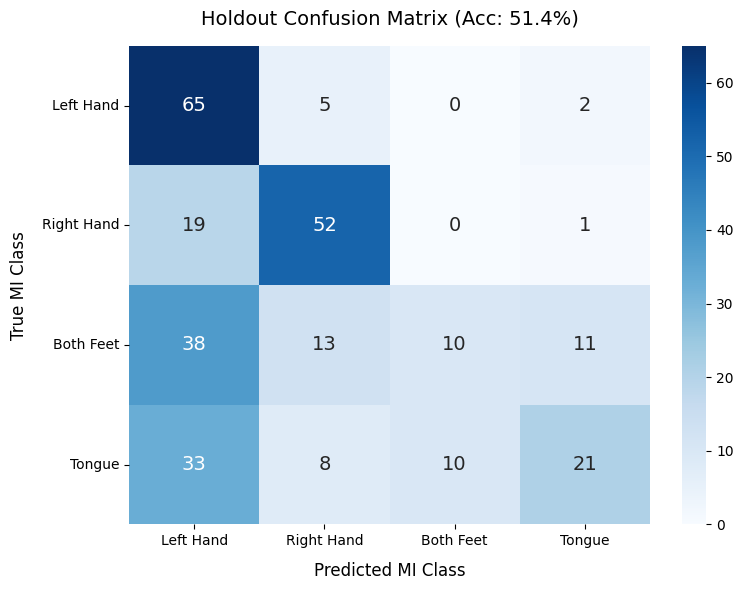

End of 3

Processing Training Data...
Extracting GDF parameters from /kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A05T.gdf...
Setting channel info structure...
Could not determine channel type of the following channels, they will be set as EEG:
EEG-Fz, EEG, EEG, EEG, EEG, EEG, EEG, EEG-C3, EEG, EEG-Cz, EEG, EEG-C4, EEG, EEG, EEG, EEG, EEG, EEG, EEG, EEG-Pz, EEG, EEG, EOG-left, EOG-central, EOG-right
Creating raw.info structure...
Reading 0 ... 686119  =      0.000 ...  2744.476 secs...


/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '769', '770', '771', '772']
Epoch [10/300] | CE Loss: 0.0580 | WC Loss: 2.7644 | Ortho Loss: 0.0019 | Train Acc: 25.69%
Epoch [20/300] | CE Loss: 0.0621 | WC Loss: 2.7615 | Ortho Loss: 0.0051 | Train Acc: 29.93%
Epoch [30/300] | CE Loss: 0.0593 | WC Loss: 2.6630 | Ortho Loss: 0.0038 | Train Acc: 33.12%
Epoch [40/300] | CE Loss: 0.0595 | WC Loss: 2.5220 | Ortho Loss: 0.0025 | Train Acc: 36.94%
Epoch [50/300] | CE Loss: 0.0548 | WC Loss: 2.3699 | Ortho Loss: 0.0085 | Train Acc: 44.65%
Epoch [60/300] | CE Loss: 0.0524 | WC Loss: 2.4826 | Ortho Loss: 0.0133 | Train Acc: 49.58%
Epoch [70/300] | CE Loss: 0.0465 | WC Loss: 2.5493 | Ortho Loss: 0.0116 | Train Acc: 55.07%
Epoch [80/300] | CE Loss: 0.0506 | WC Loss: 2.5975 | Ortho Loss: 0.0121 | Train Acc: 56.25%
Epoch [90/300] | CE Loss: 0.0466 | WC Loss: 2.6658 | Ortho Loss: 0.0122 | Train Acc: 57.08%
Epoch [100/300] | CE Loss: 0.0435 | WC Loss: 2.7086 | Ortho Loss: 

/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '783']
Applying global training normalization to evaluation data...
Reconstructing trial indices from the relative timeline clock...
Labels successfully aligned! Verification Shape: (1440,)
Total unique trials reconstructed from timeline: 288/288

🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)
Target Subject File:  A05E.gdf
Total True Trials:    288
Final True Test Acc:  52.08%



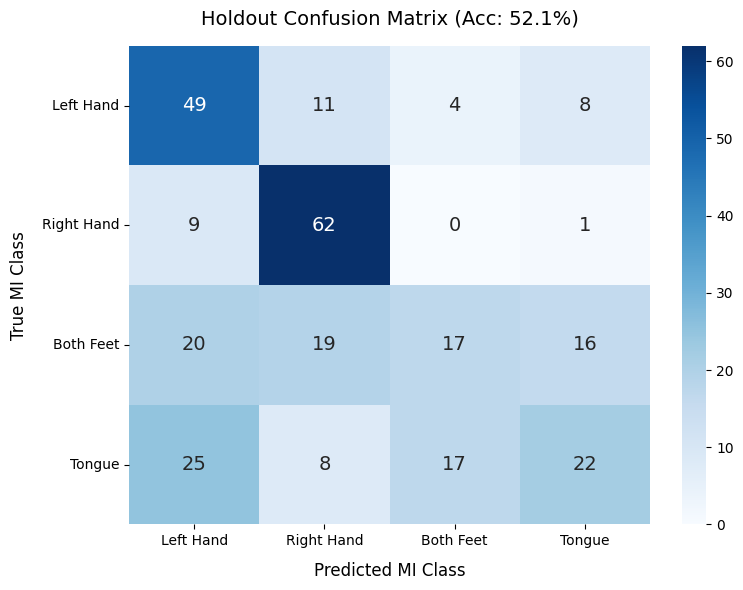

End of 4

Processing Training Data...
Extracting GDF parameters from /kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A05T.gdf...
Setting channel info structure...
Could not determine channel type of the following channels, they will be set as EEG:
EEG-Fz, EEG, EEG, EEG, EEG, EEG, EEG, EEG-C3, EEG, EEG-Cz, EEG, EEG-C4, EEG, EEG, EEG, EEG, EEG, EEG, EEG, EEG-Pz, EEG, EEG, EOG-left, EOG-central, EOG-right
Creating raw.info structure...
Reading 0 ... 686119  =      0.000 ...  2744.476 secs...


/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '769', '770', '771', '772']
Epoch [10/300] | CE Loss: 0.0553 | WC Loss: 2.9642 | Ortho Loss: 0.0025 | Train Acc: 28.12%
Epoch [20/300] | CE Loss: 0.0605 | WC Loss: 2.5219 | Ortho Loss: 0.0032 | Train Acc: 31.46%
Epoch [30/300] | CE Loss: 0.0558 | WC Loss: 2.4123 | Ortho Loss: 0.0065 | Train Acc: 39.93%
Epoch [40/300] | CE Loss: 0.0493 | WC Loss: 2.4252 | Ortho Loss: 0.0087 | Train Acc: 47.22%
Epoch [50/300] | CE Loss: 0.0504 | WC Loss: 2.4242 | Ortho Loss: 0.0118 | Train Acc: 53.26%
Epoch [60/300] | CE Loss: 0.0487 | WC Loss: 2.5590 | Ortho Loss: 0.0150 | Train Acc: 58.47%
Epoch [70/300] | CE Loss: 0.0491 | WC Loss: 2.6464 | Ortho Loss: 0.0168 | Train Acc: 61.39%
Epoch [80/300] | CE Loss: 0.0452 | WC Loss: 2.7236 | Ortho Loss: 0.0175 | Train Acc: 63.12%
Epoch [90/300] | CE Loss: 0.0415 | WC Loss: 2.8799 | Ortho Loss: 0.0181 | Train Acc: 66.67%
Epoch [100/300] | CE Loss: 0.0445 | WC Loss: 2.9685 | Ortho Loss: 

/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '783']
Applying global training normalization to evaluation data...
Reconstructing trial indices from the relative timeline clock...
Labels successfully aligned! Verification Shape: (1440,)
Total unique trials reconstructed from timeline: 288/288

🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)
Target Subject File:  A05E.gdf
Total True Trials:    288
Final True Test Acc:  54.86%



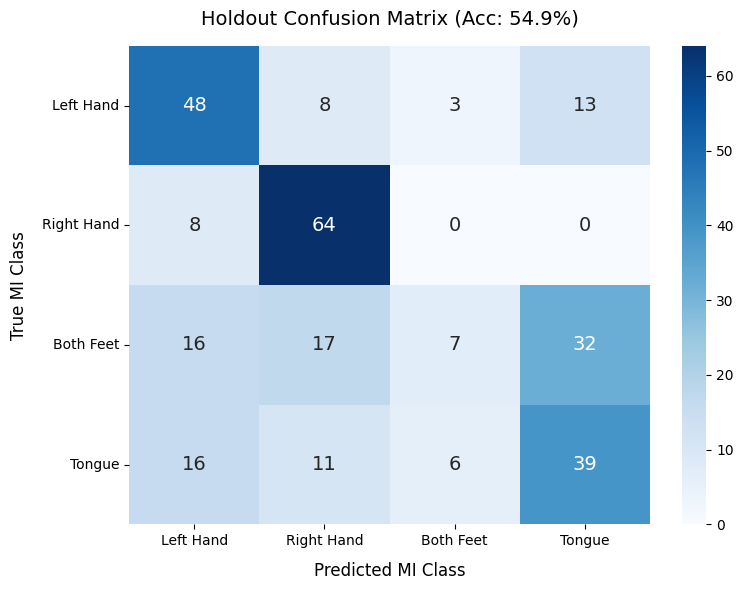

End of 5


In [13]:
lists.append(run_(5, parameters, batch_size, epochs, device, preprocessor, 0.01, 0.001))

## Subject 6


Processing Training Data...
Extracting GDF parameters from /kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A06T.gdf...
Setting channel info structure...
Could not determine channel type of the following channels, they will be set as EEG:
EEG-Fz, EEG, EEG, EEG, EEG, EEG, EEG, EEG-C3, EEG, EEG-Cz, EEG, EEG-C4, EEG, EEG, EEG, EEG, EEG, EEG, EEG, EEG-Pz, EEG, EEG, EOG-left, EOG-central, EOG-right
Creating raw.info structure...
Reading 0 ... 678979  =      0.000 ...  2715.916 secs...


/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '769', '770', '771', '772']
Epoch [10/300] | CE Loss: 0.0597 | WC Loss: 3.6168 | Ortho Loss: 0.0067 | Train Acc: 30.35%
Epoch [20/300] | CE Loss: 0.0601 | WC Loss: 3.3876 | Ortho Loss: 0.0123 | Train Acc: 35.42%
Epoch [30/300] | CE Loss: 0.0577 | WC Loss: 2.8272 | Ortho Loss: 0.0196 | Train Acc: 40.00%
Epoch [40/300] | CE Loss: 0.0545 | WC Loss: 2.9185 | Ortho Loss: 0.0195 | Train Acc: 44.65%
Epoch [50/300] | CE Loss: 0.0538 | WC Loss: 2.9687 | Ortho Loss: 0.0223 | Train Acc: 45.62%
Epoch [60/300] | CE Loss: 0.0571 | WC Loss: 3.0591 | Ortho Loss: 0.0234 | Train Acc: 48.40%
Epoch [70/300] | CE Loss: 0.0531 | WC Loss: 3.1562 | Ortho Loss: 0.0218 | Train Acc: 51.18%
Epoch [80/300] | CE Loss: 0.0567 | WC Loss: 3.2702 | Ortho Loss: 0.0198 | Train Acc: 51.94%
Epoch [90/300] | CE Loss: 0.0506 | WC Loss: 3.2332 | Ortho Loss: 0.0171 | Train Acc: 54.17%
Epoch [100/300] | CE Loss: 0.0499 | WC Loss: 3.3688 | Ortho Loss: 

/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '783']
Applying global training normalization to evaluation data...
Reconstructing trial indices from the relative timeline clock...
Labels successfully aligned! Verification Shape: (1440,)
Total unique trials reconstructed from timeline: 288/288

🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)
Target Subject File:  A06E.gdf
Total True Trials:    288
Final True Test Acc:  46.53%



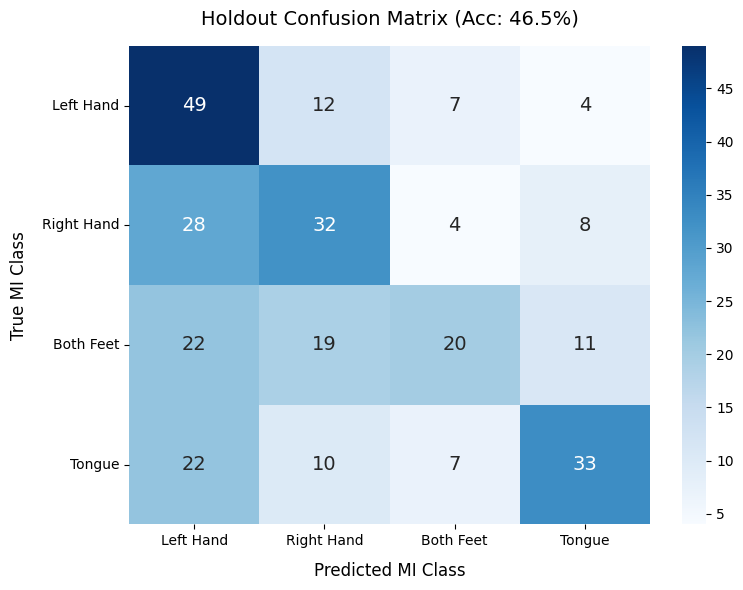

End of 1

Processing Training Data...
Extracting GDF parameters from /kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A06T.gdf...
Setting channel info structure...
Could not determine channel type of the following channels, they will be set as EEG:
EEG-Fz, EEG, EEG, EEG, EEG, EEG, EEG, EEG-C3, EEG, EEG-Cz, EEG, EEG-C4, EEG, EEG, EEG, EEG, EEG, EEG, EEG, EEG-Pz, EEG, EEG, EOG-left, EOG-central, EOG-right
Creating raw.info structure...
Reading 0 ... 678979  =      0.000 ...  2715.916 secs...


/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '769', '770', '771', '772']
Epoch [10/300] | CE Loss: 0.0630 | WC Loss: 4.6612 | Ortho Loss: 0.0055 | Train Acc: 29.58%
Epoch [20/300] | CE Loss: 0.0583 | WC Loss: 4.0647 | Ortho Loss: 0.0050 | Train Acc: 33.75%
Epoch [30/300] | CE Loss: 0.0551 | WC Loss: 3.9102 | Ortho Loss: 0.0062 | Train Acc: 38.26%
Epoch [40/300] | CE Loss: 0.0562 | WC Loss: 3.5987 | Ortho Loss: 0.0050 | Train Acc: 44.72%
Epoch [50/300] | CE Loss: 0.0537 | WC Loss: 3.4339 | Ortho Loss: 0.0048 | Train Acc: 47.43%
Epoch [60/300] | CE Loss: 0.0503 | WC Loss: 3.1460 | Ortho Loss: 0.0044 | Train Acc: 49.24%
Epoch [70/300] | CE Loss: 0.0507 | WC Loss: 3.2141 | Ortho Loss: 0.0051 | Train Acc: 53.40%
Epoch [80/300] | CE Loss: 0.0477 | WC Loss: 3.0147 | Ortho Loss: 0.0048 | Train Acc: 54.17%
Epoch [90/300] | CE Loss: 0.0522 | WC Loss: 2.9938 | Ortho Loss: 0.0048 | Train Acc: 55.21%
Epoch [100/300] | CE Loss: 0.0487 | WC Loss: 2.8834 | Ortho Loss: 

/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '783']
Applying global training normalization to evaluation data...
Reconstructing trial indices from the relative timeline clock...
Labels successfully aligned! Verification Shape: (1440,)
Total unique trials reconstructed from timeline: 288/288

🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)
Target Subject File:  A06E.gdf
Total True Trials:    288
Final True Test Acc:  47.57%



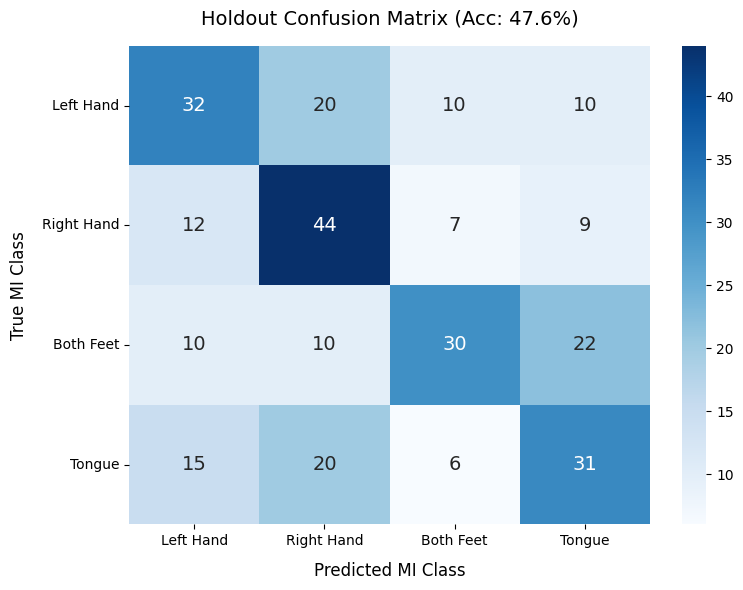

End of 2

Processing Training Data...
Extracting GDF parameters from /kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A06T.gdf...
Setting channel info structure...
Could not determine channel type of the following channels, they will be set as EEG:
EEG-Fz, EEG, EEG, EEG, EEG, EEG, EEG, EEG-C3, EEG, EEG-Cz, EEG, EEG-C4, EEG, EEG, EEG, EEG, EEG, EEG, EEG, EEG-Pz, EEG, EEG, EOG-left, EOG-central, EOG-right
Creating raw.info structure...
Reading 0 ... 678979  =      0.000 ...  2715.916 secs...


/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '769', '770', '771', '772']
Epoch [10/300] | CE Loss: 0.0583 | WC Loss: 4.2941 | Ortho Loss: 0.0050 | Train Acc: 30.83%
Epoch [20/300] | CE Loss: 0.0583 | WC Loss: 3.8996 | Ortho Loss: 0.0067 | Train Acc: 32.71%
Epoch [30/300] | CE Loss: 0.0578 | WC Loss: 3.5634 | Ortho Loss: 0.0070 | Train Acc: 39.24%
Epoch [40/300] | CE Loss: 0.0526 | WC Loss: 3.6793 | Ortho Loss: 0.0059 | Train Acc: 46.39%
Epoch [50/300] | CE Loss: 0.0523 | WC Loss: 3.7874 | Ortho Loss: 0.0074 | Train Acc: 49.38%
Epoch [60/300] | CE Loss: 0.0509 | WC Loss: 3.8677 | Ortho Loss: 0.0088 | Train Acc: 50.56%
Epoch [70/300] | CE Loss: 0.0518 | WC Loss: 3.9571 | Ortho Loss: 0.0107 | Train Acc: 52.22%
Epoch [80/300] | CE Loss: 0.0543 | WC Loss: 3.9536 | Ortho Loss: 0.0118 | Train Acc: 56.39%
Epoch [90/300] | CE Loss: 0.0561 | WC Loss: 4.0490 | Ortho Loss: 0.0130 | Train Acc: 55.42%
Epoch [100/300] | CE Loss: 0.0450 | WC Loss: 4.0820 | Ortho Loss: 

/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '783']
Applying global training normalization to evaluation data...
Reconstructing trial indices from the relative timeline clock...
Labels successfully aligned! Verification Shape: (1440,)
Total unique trials reconstructed from timeline: 288/288

🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)
Target Subject File:  A06E.gdf
Total True Trials:    288
Final True Test Acc:  48.26%



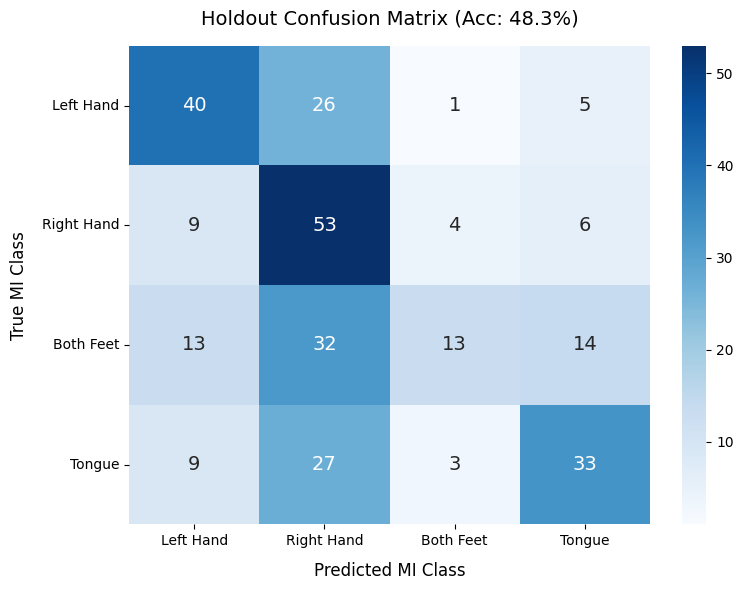

End of 3

Processing Training Data...
Extracting GDF parameters from /kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A06T.gdf...
Setting channel info structure...
Could not determine channel type of the following channels, they will be set as EEG:
EEG-Fz, EEG, EEG, EEG, EEG, EEG, EEG, EEG-C3, EEG, EEG-Cz, EEG, EEG-C4, EEG, EEG, EEG, EEG, EEG, EEG, EEG, EEG-Pz, EEG, EEG, EOG-left, EOG-central, EOG-right
Creating raw.info structure...
Reading 0 ... 678979  =      0.000 ...  2715.916 secs...


/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '769', '770', '771', '772']
Epoch [10/300] | CE Loss: 0.0649 | WC Loss: 4.5578 | Ortho Loss: 0.0052 | Train Acc: 28.19%
Epoch [20/300] | CE Loss: 0.0632 | WC Loss: 4.1569 | Ortho Loss: 0.0077 | Train Acc: 33.75%
Epoch [30/300] | CE Loss: 0.0576 | WC Loss: 3.3267 | Ortho Loss: 0.0100 | Train Acc: 38.89%
Epoch [40/300] | CE Loss: 0.0566 | WC Loss: 3.1826 | Ortho Loss: 0.0119 | Train Acc: 43.47%
Epoch [50/300] | CE Loss: 0.0540 | WC Loss: 3.1667 | Ortho Loss: 0.0109 | Train Acc: 47.29%
Epoch [60/300] | CE Loss: 0.0514 | WC Loss: 3.1851 | Ortho Loss: 0.0114 | Train Acc: 50.90%
Epoch [70/300] | CE Loss: 0.0505 | WC Loss: 3.0687 | Ortho Loss: 0.0108 | Train Acc: 52.22%
Epoch [80/300] | CE Loss: 0.0531 | WC Loss: 3.0243 | Ortho Loss: 0.0104 | Train Acc: 54.72%
Epoch [90/300] | CE Loss: 0.0482 | WC Loss: 3.0685 | Ortho Loss: 0.0090 | Train Acc: 55.49%
Epoch [100/300] | CE Loss: 0.0449 | WC Loss: 3.1053 | Ortho Loss: 

/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '783']
Applying global training normalization to evaluation data...
Reconstructing trial indices from the relative timeline clock...
Labels successfully aligned! Verification Shape: (1440,)
Total unique trials reconstructed from timeline: 288/288

🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)
Target Subject File:  A06E.gdf
Total True Trials:    288
Final True Test Acc:  49.31%



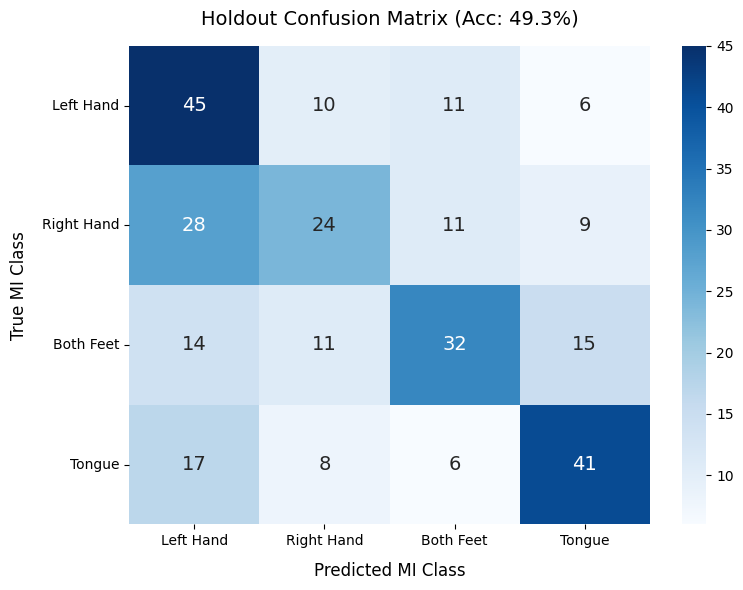

End of 4

Processing Training Data...
Extracting GDF parameters from /kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A06T.gdf...
Setting channel info structure...
Could not determine channel type of the following channels, they will be set as EEG:
EEG-Fz, EEG, EEG, EEG, EEG, EEG, EEG, EEG-C3, EEG, EEG-Cz, EEG, EEG-C4, EEG, EEG, EEG, EEG, EEG, EEG, EEG, EEG-Pz, EEG, EEG, EOG-left, EOG-central, EOG-right
Creating raw.info structure...
Reading 0 ... 678979  =      0.000 ...  2715.916 secs...


/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '769', '770', '771', '772']
Epoch [10/300] | CE Loss: 0.0578 | WC Loss: 3.2097 | Ortho Loss: 0.0075 | Train Acc: 29.10%
Epoch [20/300] | CE Loss: 0.0559 | WC Loss: 2.5672 | Ortho Loss: 0.0125 | Train Acc: 34.38%
Epoch [30/300] | CE Loss: 0.0562 | WC Loss: 2.3548 | Ortho Loss: 0.0229 | Train Acc: 43.33%
Epoch [40/300] | CE Loss: 0.0532 | WC Loss: 2.2782 | Ortho Loss: 0.0308 | Train Acc: 47.50%
Epoch [50/300] | CE Loss: 0.0540 | WC Loss: 2.5673 | Ortho Loss: 0.0321 | Train Acc: 50.14%
Epoch [60/300] | CE Loss: 0.0506 | WC Loss: 2.6432 | Ortho Loss: 0.0308 | Train Acc: 52.85%
Epoch [70/300] | CE Loss: 0.0480 | WC Loss: 2.7100 | Ortho Loss: 0.0322 | Train Acc: 55.35%
Epoch [80/300] | CE Loss: 0.0519 | WC Loss: 2.7103 | Ortho Loss: 0.0338 | Train Acc: 56.67%
Epoch [90/300] | CE Loss: 0.0489 | WC Loss: 2.7389 | Ortho Loss: 0.0338 | Train Acc: 56.53%
Epoch [100/300] | CE Loss: 0.0507 | WC Loss: 2.6430 | Ortho Loss: 

/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '783']
Applying global training normalization to evaluation data...
Reconstructing trial indices from the relative timeline clock...
Labels successfully aligned! Verification Shape: (1440,)
Total unique trials reconstructed from timeline: 288/288

🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)
Target Subject File:  A06E.gdf
Total True Trials:    288
Final True Test Acc:  49.65%



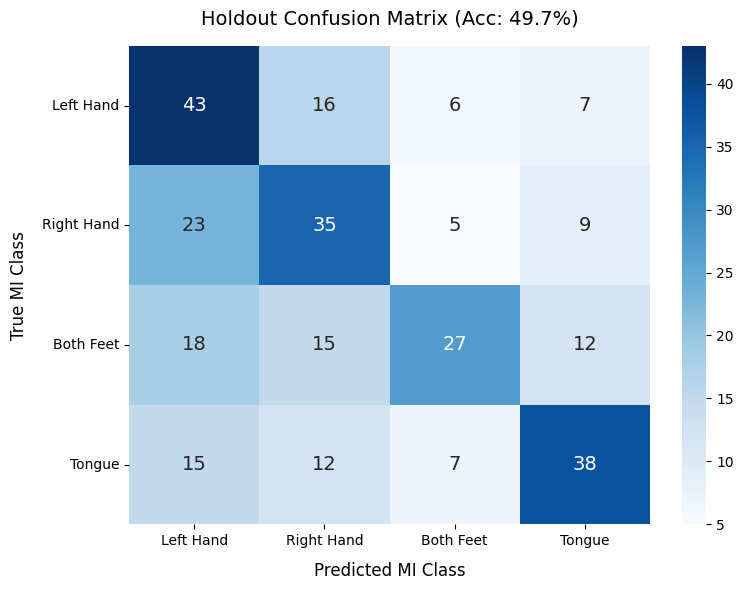

End of 5


In [14]:
lists.append(run_(6, parameters, batch_size, epochs, device, preprocessor, 0.01, 0.001))

## Subject 7


Processing Training Data...
Extracting GDF parameters from /kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A07T.gdf...
Setting channel info structure...
Could not determine channel type of the following channels, they will be set as EEG:
EEG-Fz, EEG, EEG, EEG, EEG, EEG, EEG, EEG-C3, EEG, EEG-Cz, EEG, EEG-C4, EEG, EEG, EEG, EEG, EEG, EEG, EEG, EEG-Pz, EEG, EEG, EOG-left, EOG-central, EOG-right
Creating raw.info structure...
Reading 0 ... 681070  =      0.000 ...  2724.280 secs...


/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '769', '770', '771', '772']
Epoch [10/300] | CE Loss: 0.0590 | WC Loss: 2.1521 | Ortho Loss: 0.0031 | Train Acc: 30.49%
Epoch [20/300] | CE Loss: 0.0547 | WC Loss: 2.0581 | Ortho Loss: 0.0075 | Train Acc: 40.83%
Epoch [30/300] | CE Loss: 0.0525 | WC Loss: 2.1199 | Ortho Loss: 0.0067 | Train Acc: 49.44%
Epoch [40/300] | CE Loss: 0.0503 | WC Loss: 2.2224 | Ortho Loss: 0.0070 | Train Acc: 58.26%
Epoch [50/300] | CE Loss: 0.0436 | WC Loss: 2.4355 | Ortho Loss: 0.0085 | Train Acc: 61.60%
Epoch [60/300] | CE Loss: 0.0409 | WC Loss: 2.4732 | Ortho Loss: 0.0131 | Train Acc: 65.21%
Epoch [70/300] | CE Loss: 0.0440 | WC Loss: 2.6745 | Ortho Loss: 0.0156 | Train Acc: 69.51%
Epoch [80/300] | CE Loss: 0.0367 | WC Loss: 2.8225 | Ortho Loss: 0.0149 | Train Acc: 75.21%
Epoch [90/300] | CE Loss: 0.0368 | WC Loss: 2.9332 | Ortho Loss: 0.0152 | Train Acc: 74.51%
Epoch [100/300] | CE Loss: 0.0413 | WC Loss: 3.0204 | Ortho Loss: 

/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '783']
Applying global training normalization to evaluation data...
Reconstructing trial indices from the relative timeline clock...
Labels successfully aligned! Verification Shape: (1440,)
Total unique trials reconstructed from timeline: 288/288

🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)
Target Subject File:  A07E.gdf
Total True Trials:    288
Final True Test Acc:  75.00%



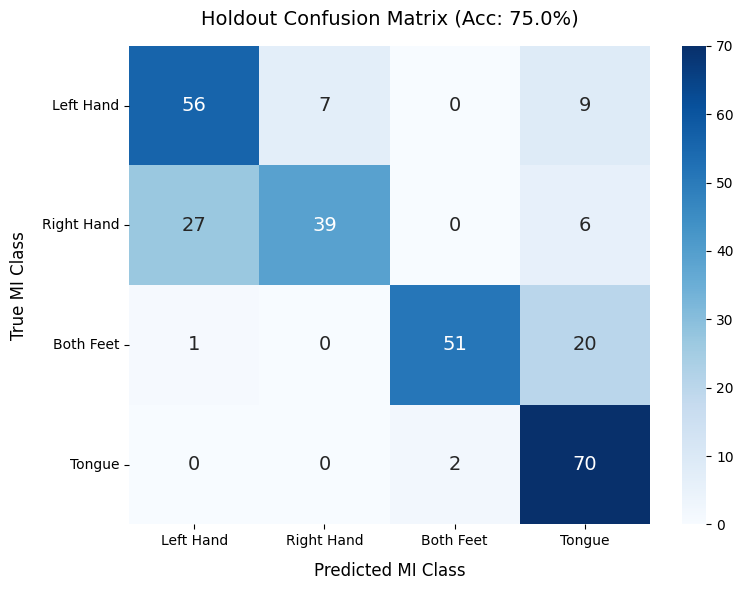

End of 1

Processing Training Data...
Extracting GDF parameters from /kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A07T.gdf...
Setting channel info structure...
Could not determine channel type of the following channels, they will be set as EEG:
EEG-Fz, EEG, EEG, EEG, EEG, EEG, EEG, EEG-C3, EEG, EEG-Cz, EEG, EEG-C4, EEG, EEG, EEG, EEG, EEG, EEG, EEG, EEG-Pz, EEG, EEG, EOG-left, EOG-central, EOG-right
Creating raw.info structure...
Reading 0 ... 681070  =      0.000 ...  2724.280 secs...


/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '769', '770', '771', '772']
Epoch [10/300] | CE Loss: 0.0548 | WC Loss: 3.9366 | Ortho Loss: 0.0199 | Train Acc: 33.06%
Epoch [20/300] | CE Loss: 0.0550 | WC Loss: 4.1965 | Ortho Loss: 0.0172 | Train Acc: 47.29%
Epoch [30/300] | CE Loss: 0.0464 | WC Loss: 4.4382 | Ortho Loss: 0.0178 | Train Acc: 55.14%
Epoch [40/300] | CE Loss: 0.0464 | WC Loss: 4.6479 | Ortho Loss: 0.0170 | Train Acc: 64.79%
Epoch [50/300] | CE Loss: 0.0413 | WC Loss: 4.8861 | Ortho Loss: 0.0184 | Train Acc: 70.21%
Epoch [60/300] | CE Loss: 0.0419 | WC Loss: 5.0725 | Ortho Loss: 0.0208 | Train Acc: 71.32%
Epoch [70/300] | CE Loss: 0.0407 | WC Loss: 5.1659 | Ortho Loss: 0.0239 | Train Acc: 74.86%
Epoch [80/300] | CE Loss: 0.0401 | WC Loss: 5.3460 | Ortho Loss: 0.0263 | Train Acc: 78.54%
Epoch [90/300] | CE Loss: 0.0388 | WC Loss: 5.4193 | Ortho Loss: 0.0278 | Train Acc: 78.33%
Epoch [100/300] | CE Loss: 0.0340 | WC Loss: 5.4828 | Ortho Loss: 

/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '783']
Applying global training normalization to evaluation data...
Reconstructing trial indices from the relative timeline clock...
Labels successfully aligned! Verification Shape: (1440,)
Total unique trials reconstructed from timeline: 288/288

🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)
Target Subject File:  A07E.gdf
Total True Trials:    288
Final True Test Acc:  75.69%



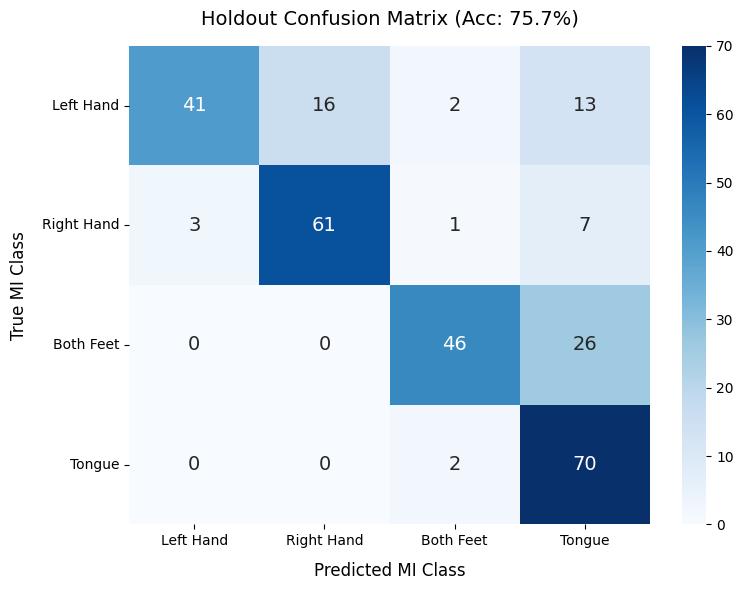

End of 2

Processing Training Data...
Extracting GDF parameters from /kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A07T.gdf...
Setting channel info structure...
Could not determine channel type of the following channels, they will be set as EEG:
EEG-Fz, EEG, EEG, EEG, EEG, EEG, EEG, EEG-C3, EEG, EEG-Cz, EEG, EEG-C4, EEG, EEG, EEG, EEG, EEG, EEG, EEG, EEG-Pz, EEG, EEG, EOG-left, EOG-central, EOG-right
Creating raw.info structure...
Reading 0 ... 681070  =      0.000 ...  2724.280 secs...


/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '769', '770', '771', '772']
Epoch [10/300] | CE Loss: 0.0643 | WC Loss: 2.7168 | Ortho Loss: 0.0142 | Train Acc: 33.12%
Epoch [20/300] | CE Loss: 0.0521 | WC Loss: 2.7223 | Ortho Loss: 0.0136 | Train Acc: 47.57%
Epoch [30/300] | CE Loss: 0.0491 | WC Loss: 2.8147 | Ortho Loss: 0.0167 | Train Acc: 57.71%
Epoch [40/300] | CE Loss: 0.0421 | WC Loss: 2.6482 | Ortho Loss: 0.0210 | Train Acc: 63.06%
Epoch [50/300] | CE Loss: 0.0420 | WC Loss: 2.4780 | Ortho Loss: 0.0247 | Train Acc: 68.54%
Epoch [60/300] | CE Loss: 0.0408 | WC Loss: 2.4966 | Ortho Loss: 0.0278 | Train Acc: 71.11%
Epoch [70/300] | CE Loss: 0.0389 | WC Loss: 2.5140 | Ortho Loss: 0.0300 | Train Acc: 75.14%
Epoch [80/300] | CE Loss: 0.0331 | WC Loss: 2.5389 | Ortho Loss: 0.0292 | Train Acc: 76.39%
Epoch [90/300] | CE Loss: 0.0382 | WC Loss: 2.5493 | Ortho Loss: 0.0300 | Train Acc: 77.99%
Epoch [100/300] | CE Loss: 0.0337 | WC Loss: 2.5708 | Ortho Loss: 

/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '783']
Applying global training normalization to evaluation data...
Reconstructing trial indices from the relative timeline clock...
Labels successfully aligned! Verification Shape: (1440,)
Total unique trials reconstructed from timeline: 288/288

🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)
Target Subject File:  A07E.gdf
Total True Trials:    288
Final True Test Acc:  70.49%



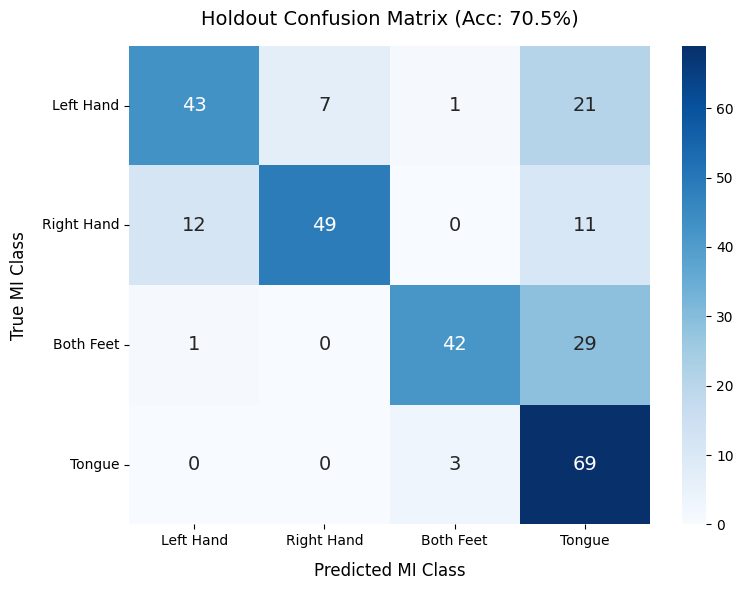

End of 3

Processing Training Data...
Extracting GDF parameters from /kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A07T.gdf...
Setting channel info structure...
Could not determine channel type of the following channels, they will be set as EEG:
EEG-Fz, EEG, EEG, EEG, EEG, EEG, EEG, EEG-C3, EEG, EEG-Cz, EEG, EEG-C4, EEG, EEG, EEG, EEG, EEG, EEG, EEG, EEG-Pz, EEG, EEG, EOG-left, EOG-central, EOG-right
Creating raw.info structure...
Reading 0 ... 681070  =      0.000 ...  2724.280 secs...


/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '769', '770', '771', '772']
Epoch [10/300] | CE Loss: 0.0571 | WC Loss: 3.8749 | Ortho Loss: 0.0114 | Train Acc: 30.83%
Epoch [20/300] | CE Loss: 0.0577 | WC Loss: 3.9114 | Ortho Loss: 0.0193 | Train Acc: 39.44%
Epoch [30/300] | CE Loss: 0.0531 | WC Loss: 3.9999 | Ortho Loss: 0.0180 | Train Acc: 46.88%
Epoch [40/300] | CE Loss: 0.0541 | WC Loss: 3.9837 | Ortho Loss: 0.0194 | Train Acc: 53.75%
Epoch [50/300] | CE Loss: 0.0469 | WC Loss: 3.8758 | Ortho Loss: 0.0209 | Train Acc: 62.29%
Epoch [60/300] | CE Loss: 0.0447 | WC Loss: 3.9071 | Ortho Loss: 0.0138 | Train Acc: 71.04%
Epoch [70/300] | CE Loss: 0.0429 | WC Loss: 4.0415 | Ortho Loss: 0.0116 | Train Acc: 74.58%
Epoch [80/300] | CE Loss: 0.0374 | WC Loss: 4.1764 | Ortho Loss: 0.0115 | Train Acc: 74.51%
Epoch [90/300] | CE Loss: 0.0371 | WC Loss: 4.2174 | Ortho Loss: 0.0116 | Train Acc: 77.64%
Epoch [100/300] | CE Loss: 0.0360 | WC Loss: 4.3246 | Ortho Loss: 

/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '783']
Applying global training normalization to evaluation data...
Reconstructing trial indices from the relative timeline clock...
Labels successfully aligned! Verification Shape: (1440,)
Total unique trials reconstructed from timeline: 288/288

🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)
Target Subject File:  A07E.gdf
Total True Trials:    288
Final True Test Acc:  72.22%



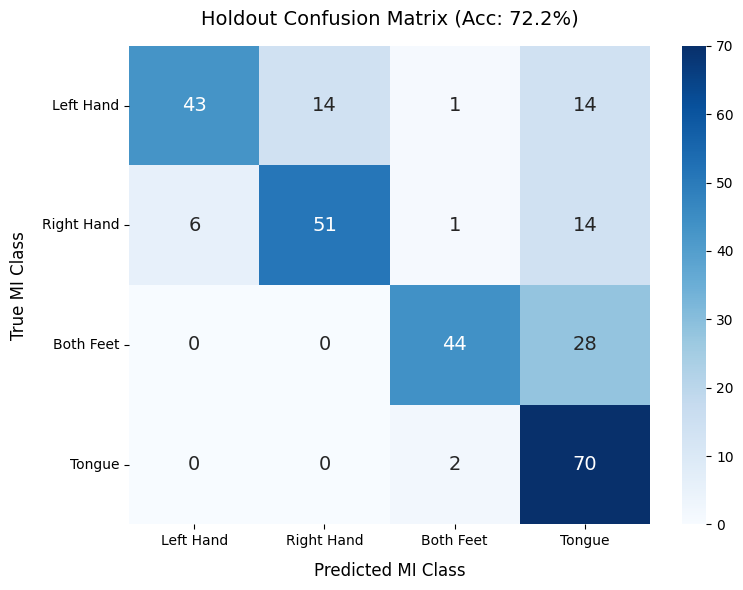

End of 4

Processing Training Data...
Extracting GDF parameters from /kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A07T.gdf...
Setting channel info structure...
Could not determine channel type of the following channels, they will be set as EEG:
EEG-Fz, EEG, EEG, EEG, EEG, EEG, EEG, EEG-C3, EEG, EEG-Cz, EEG, EEG-C4, EEG, EEG, EEG, EEG, EEG, EEG, EEG, EEG-Pz, EEG, EEG, EOG-left, EOG-central, EOG-right
Creating raw.info structure...
Reading 0 ... 681070  =      0.000 ...  2724.280 secs...


/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '769', '770', '771', '772']
Epoch [10/300] | CE Loss: 0.0598 | WC Loss: 2.8216 | Ortho Loss: 0.0118 | Train Acc: 29.31%
Epoch [20/300] | CE Loss: 0.0555 | WC Loss: 2.1969 | Ortho Loss: 0.0344 | Train Acc: 40.97%
Epoch [30/300] | CE Loss: 0.0485 | WC Loss: 1.9666 | Ortho Loss: 0.0626 | Train Acc: 54.51%
Epoch [40/300] | CE Loss: 0.0496 | WC Loss: 1.8380 | Ortho Loss: 0.0718 | Train Acc: 57.64%
Epoch [50/300] | CE Loss: 0.0487 | WC Loss: 1.9306 | Ortho Loss: 0.0787 | Train Acc: 64.51%
Epoch [60/300] | CE Loss: 0.0461 | WC Loss: 2.1252 | Ortho Loss: 0.0880 | Train Acc: 64.79%
Epoch [70/300] | CE Loss: 0.0417 | WC Loss: 2.1196 | Ortho Loss: 0.0973 | Train Acc: 66.67%
Epoch [80/300] | CE Loss: 0.0416 | WC Loss: 2.2198 | Ortho Loss: 0.1031 | Train Acc: 71.81%
Epoch [90/300] | CE Loss: 0.0372 | WC Loss: 2.2712 | Ortho Loss: 0.1047 | Train Acc: 71.39%
Epoch [100/300] | CE Loss: 0.0354 | WC Loss: 2.3120 | Ortho Loss: 

/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '783']
Applying global training normalization to evaluation data...
Reconstructing trial indices from the relative timeline clock...
Labels successfully aligned! Verification Shape: (1440,)
Total unique trials reconstructed from timeline: 288/288

🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)
Target Subject File:  A07E.gdf
Total True Trials:    288
Final True Test Acc:  65.62%



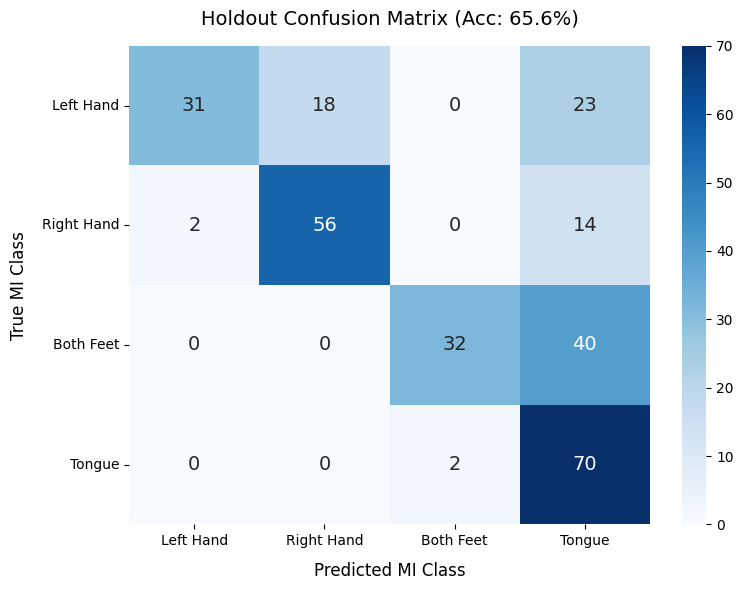

End of 5


In [15]:
lists.append(run_(7, parameters, batch_size, epochs, device, preprocessor, 0.01, 0.001))

## Subject 8


Processing Training Data...
Extracting GDF parameters from /kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A08T.gdf...
Setting channel info structure...
Could not determine channel type of the following channels, they will be set as EEG:
EEG-Fz, EEG, EEG, EEG, EEG, EEG, EEG, EEG-C3, EEG, EEG-Cz, EEG, EEG-C4, EEG, EEG, EEG, EEG, EEG, EEG, EEG, EEG-Pz, EEG, EEG, EOG-left, EOG-central, EOG-right
Creating raw.info structure...
Reading 0 ... 675269  =      0.000 ...  2701.076 secs...


/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '769', '770', '771', '772']
Epoch [10/300] | CE Loss: 0.0606 | WC Loss: 2.8336 | Ortho Loss: 0.0124 | Train Acc: 33.96%
Epoch [20/300] | CE Loss: 0.0562 | WC Loss: 3.0400 | Ortho Loss: 0.0078 | Train Acc: 41.88%
Epoch [30/300] | CE Loss: 0.0510 | WC Loss: 3.2172 | Ortho Loss: 0.0052 | Train Acc: 51.60%
Epoch [40/300] | CE Loss: 0.0437 | WC Loss: 3.4876 | Ortho Loss: 0.0064 | Train Acc: 58.61%
Epoch [50/300] | CE Loss: 0.0510 | WC Loss: 4.0181 | Ortho Loss: 0.0106 | Train Acc: 65.97%
Epoch [60/300] | CE Loss: 0.0409 | WC Loss: 4.3915 | Ortho Loss: 0.0102 | Train Acc: 68.89%
Epoch [70/300] | CE Loss: 0.0412 | WC Loss: 4.5233 | Ortho Loss: 0.0097 | Train Acc: 70.97%
Epoch [80/300] | CE Loss: 0.0420 | WC Loss: 4.5862 | Ortho Loss: 0.0121 | Train Acc: 73.19%
Epoch [90/300] | CE Loss: 0.0382 | WC Loss: 4.6507 | Ortho Loss: 0.0163 | Train Acc: 73.54%
Epoch [100/300] | CE Loss: 0.0359 | WC Loss: 4.7928 | Ortho Loss: 

/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '783']
Applying global training normalization to evaluation data...
Reconstructing trial indices from the relative timeline clock...
Labels successfully aligned! Verification Shape: (1440,)
Total unique trials reconstructed from timeline: 288/288

🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)
Target Subject File:  A08E.gdf
Total True Trials:    288
Final True Test Acc:  77.08%



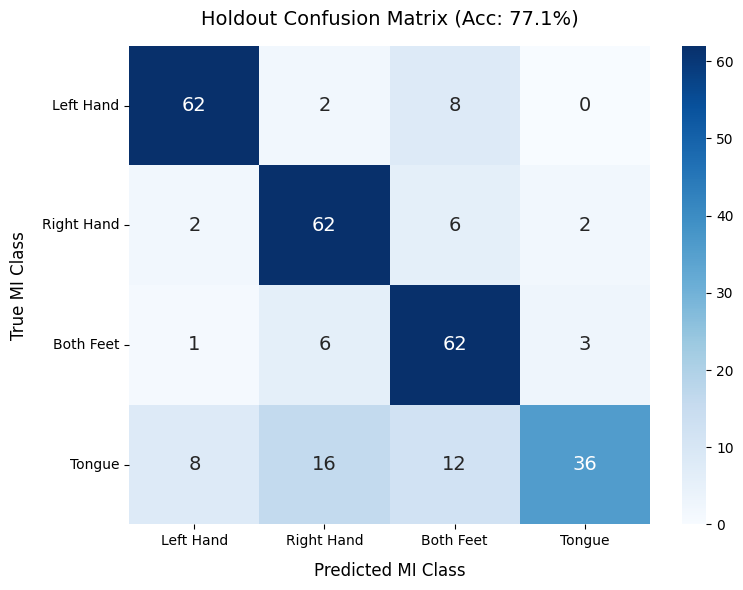

End of 1

Processing Training Data...
Extracting GDF parameters from /kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A08T.gdf...
Setting channel info structure...
Could not determine channel type of the following channels, they will be set as EEG:
EEG-Fz, EEG, EEG, EEG, EEG, EEG, EEG, EEG-C3, EEG, EEG-Cz, EEG, EEG-C4, EEG, EEG, EEG, EEG, EEG, EEG, EEG, EEG-Pz, EEG, EEG, EOG-left, EOG-central, EOG-right
Creating raw.info structure...
Reading 0 ... 675269  =      0.000 ...  2701.076 secs...


/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '769', '770', '771', '772']
Epoch [10/300] | CE Loss: 0.0612 | WC Loss: 3.1486 | Ortho Loss: 0.0056 | Train Acc: 33.61%
Epoch [20/300] | CE Loss: 0.0528 | WC Loss: 3.6731 | Ortho Loss: 0.0137 | Train Acc: 47.22%
Epoch [30/300] | CE Loss: 0.0544 | WC Loss: 4.0405 | Ortho Loss: 0.0171 | Train Acc: 58.82%
Epoch [40/300] | CE Loss: 0.0489 | WC Loss: 4.2674 | Ortho Loss: 0.0109 | Train Acc: 67.43%
Epoch [50/300] | CE Loss: 0.0421 | WC Loss: 4.5400 | Ortho Loss: 0.0069 | Train Acc: 70.28%
Epoch [60/300] | CE Loss: 0.0418 | WC Loss: 4.7248 | Ortho Loss: 0.0054 | Train Acc: 72.50%
Epoch [70/300] | CE Loss: 0.0370 | WC Loss: 4.7182 | Ortho Loss: 0.0064 | Train Acc: 75.69%
Epoch [80/300] | CE Loss: 0.0336 | WC Loss: 4.7676 | Ortho Loss: 0.0061 | Train Acc: 76.94%
Epoch [90/300] | CE Loss: 0.0370 | WC Loss: 4.9180 | Ortho Loss: 0.0069 | Train Acc: 77.22%
Epoch [100/300] | CE Loss: 0.0352 | WC Loss: 4.9368 | Ortho Loss: 

/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '783']
Applying global training normalization to evaluation data...
Reconstructing trial indices from the relative timeline clock...
Labels successfully aligned! Verification Shape: (1440,)
Total unique trials reconstructed from timeline: 288/288

🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)
Target Subject File:  A08E.gdf
Total True Trials:    288
Final True Test Acc:  79.17%



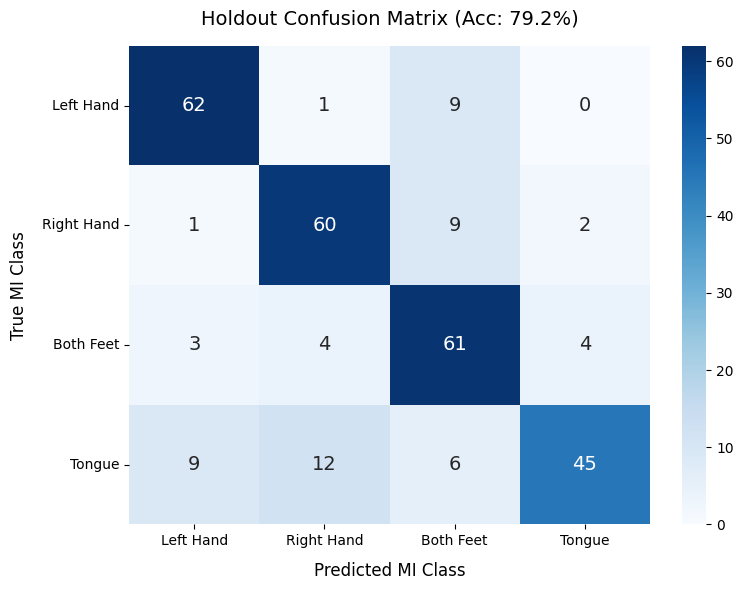

End of 2

Processing Training Data...
Extracting GDF parameters from /kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A08T.gdf...
Setting channel info structure...
Could not determine channel type of the following channels, they will be set as EEG:
EEG-Fz, EEG, EEG, EEG, EEG, EEG, EEG, EEG-C3, EEG, EEG-Cz, EEG, EEG-C4, EEG, EEG, EEG, EEG, EEG, EEG, EEG, EEG-Pz, EEG, EEG, EOG-left, EOG-central, EOG-right
Creating raw.info structure...
Reading 0 ... 675269  =      0.000 ...  2701.076 secs...


/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '769', '770', '771', '772']
Epoch [10/300] | CE Loss: 0.0564 | WC Loss: 4.2471 | Ortho Loss: 0.0053 | Train Acc: 36.67%
Epoch [20/300] | CE Loss: 0.0545 | WC Loss: 4.7413 | Ortho Loss: 0.0107 | Train Acc: 53.19%
Epoch [30/300] | CE Loss: 0.0447 | WC Loss: 5.0906 | Ortho Loss: 0.0100 | Train Acc: 63.96%
Epoch [40/300] | CE Loss: 0.0420 | WC Loss: 5.4043 | Ortho Loss: 0.0136 | Train Acc: 67.85%
Epoch [50/300] | CE Loss: 0.0425 | WC Loss: 5.5482 | Ortho Loss: 0.0175 | Train Acc: 71.81%
Epoch [60/300] | CE Loss: 0.0425 | WC Loss: 5.6974 | Ortho Loss: 0.0196 | Train Acc: 74.17%
Epoch [70/300] | CE Loss: 0.0341 | WC Loss: 5.7745 | Ortho Loss: 0.0221 | Train Acc: 72.99%
Epoch [80/300] | CE Loss: 0.0423 | WC Loss: 5.8104 | Ortho Loss: 0.0221 | Train Acc: 74.65%
Epoch [90/300] | CE Loss: 0.0367 | WC Loss: 5.8540 | Ortho Loss: 0.0225 | Train Acc: 76.39%
Epoch [100/300] | CE Loss: 0.0350 | WC Loss: 5.7833 | Ortho Loss: 

/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '783']
Applying global training normalization to evaluation data...
Reconstructing trial indices from the relative timeline clock...
Labels successfully aligned! Verification Shape: (1440,)
Total unique trials reconstructed from timeline: 288/288

🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)
Target Subject File:  A08E.gdf
Total True Trials:    288
Final True Test Acc:  77.08%



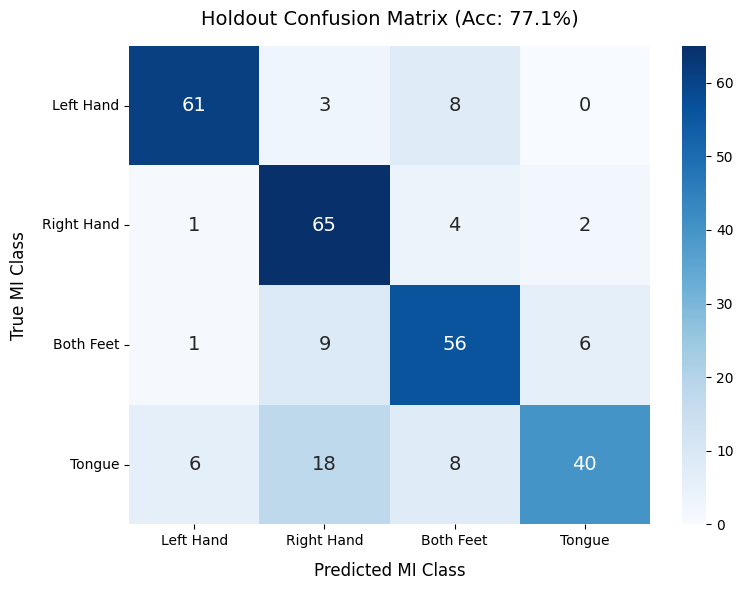

End of 3

Processing Training Data...
Extracting GDF parameters from /kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A08T.gdf...
Setting channel info structure...
Could not determine channel type of the following channels, they will be set as EEG:
EEG-Fz, EEG, EEG, EEG, EEG, EEG, EEG, EEG-C3, EEG, EEG-Cz, EEG, EEG-C4, EEG, EEG, EEG, EEG, EEG, EEG, EEG, EEG-Pz, EEG, EEG, EOG-left, EOG-central, EOG-right
Creating raw.info structure...
Reading 0 ... 675269  =      0.000 ...  2701.076 secs...


/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '769', '770', '771', '772']
Epoch [10/300] | CE Loss: 0.0586 | WC Loss: 1.9149 | Ortho Loss: 0.0102 | Train Acc: 30.35%
Epoch [20/300] | CE Loss: 0.0579 | WC Loss: 2.3346 | Ortho Loss: 0.0092 | Train Acc: 43.12%
Epoch [30/300] | CE Loss: 0.0492 | WC Loss: 2.6567 | Ortho Loss: 0.0134 | Train Acc: 53.68%
Epoch [40/300] | CE Loss: 0.0487 | WC Loss: 3.2811 | Ortho Loss: 0.0131 | Train Acc: 59.86%
Epoch [50/300] | CE Loss: 0.0472 | WC Loss: 3.4257 | Ortho Loss: 0.0136 | Train Acc: 64.65%
Epoch [60/300] | CE Loss: 0.0446 | WC Loss: 3.5849 | Ortho Loss: 0.0124 | Train Acc: 68.06%
Epoch [70/300] | CE Loss: 0.0360 | WC Loss: 3.5971 | Ortho Loss: 0.0128 | Train Acc: 71.11%
Epoch [80/300] | CE Loss: 0.0406 | WC Loss: 3.7236 | Ortho Loss: 0.0139 | Train Acc: 70.97%
Epoch [90/300] | CE Loss: 0.0426 | WC Loss: 3.7310 | Ortho Loss: 0.0140 | Train Acc: 70.69%
Epoch [100/300] | CE Loss: 0.0341 | WC Loss: 3.7421 | Ortho Loss: 

/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '783']
Applying global training normalization to evaluation data...
Reconstructing trial indices from the relative timeline clock...
Labels successfully aligned! Verification Shape: (1440,)
Total unique trials reconstructed from timeline: 288/288

🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)
Target Subject File:  A08E.gdf
Total True Trials:    288
Final True Test Acc:  76.74%



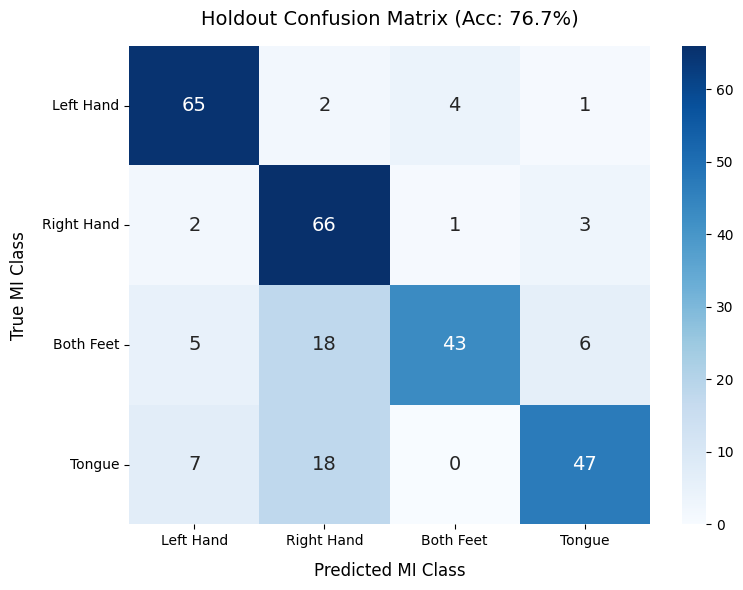

End of 4

Processing Training Data...
Extracting GDF parameters from /kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A08T.gdf...
Setting channel info structure...
Could not determine channel type of the following channels, they will be set as EEG:
EEG-Fz, EEG, EEG, EEG, EEG, EEG, EEG, EEG-C3, EEG, EEG-Cz, EEG, EEG-C4, EEG, EEG, EEG, EEG, EEG, EEG, EEG, EEG-Pz, EEG, EEG, EOG-left, EOG-central, EOG-right
Creating raw.info structure...
Reading 0 ... 675269  =      0.000 ...  2701.076 secs...


/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '769', '770', '771', '772']
Epoch [10/300] | CE Loss: 0.0600 | WC Loss: 3.3995 | Ortho Loss: 0.0128 | Train Acc: 35.83%
Epoch [20/300] | CE Loss: 0.0523 | WC Loss: 4.1882 | Ortho Loss: 0.0169 | Train Acc: 49.79%
Epoch [30/300] | CE Loss: 0.0459 | WC Loss: 4.5672 | Ortho Loss: 0.0135 | Train Acc: 60.56%
Epoch [40/300] | CE Loss: 0.0431 | WC Loss: 4.7496 | Ortho Loss: 0.0123 | Train Acc: 69.38%
Epoch [50/300] | CE Loss: 0.0433 | WC Loss: 5.0397 | Ortho Loss: 0.0138 | Train Acc: 72.64%
Epoch [60/300] | CE Loss: 0.0434 | WC Loss: 5.2673 | Ortho Loss: 0.0141 | Train Acc: 73.33%
Epoch [70/300] | CE Loss: 0.0318 | WC Loss: 5.3756 | Ortho Loss: 0.0156 | Train Acc: 75.42%
Epoch [80/300] | CE Loss: 0.0363 | WC Loss: 5.6316 | Ortho Loss: 0.0172 | Train Acc: 74.10%
Epoch [90/300] | CE Loss: 0.0397 | WC Loss: 5.8983 | Ortho Loss: 0.0180 | Train Acc: 75.69%
Epoch [100/300] | CE Loss: 0.0392 | WC Loss: 6.0567 | Ortho Loss: 

/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '783']
Applying global training normalization to evaluation data...
Reconstructing trial indices from the relative timeline clock...
Labels successfully aligned! Verification Shape: (1440,)
Total unique trials reconstructed from timeline: 288/288

🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)
Target Subject File:  A08E.gdf
Total True Trials:    288
Final True Test Acc:  76.39%



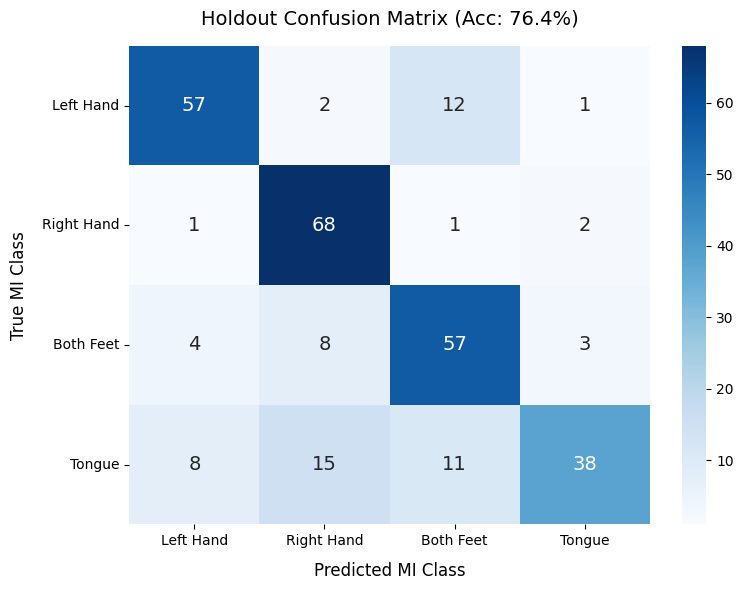

End of 5


In [16]:
lists.append(run_(8, parameters, batch_size, epochs, device, preprocessor, 0.01, 0.001))

## Subject 9


Processing Training Data...
Extracting GDF parameters from /kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A09T.gdf...
Setting channel info structure...
Could not determine channel type of the following channels, they will be set as EEG:
EEG-Fz, EEG, EEG, EEG, EEG, EEG, EEG, EEG-C3, EEG, EEG-Cz, EEG, EEG-C4, EEG, EEG, EEG, EEG, EEG, EEG, EEG, EEG-Pz, EEG, EEG, EOG-left, EOG-central, EOG-right
Creating raw.info structure...
Reading 0 ... 673327  =      0.000 ...  2693.308 secs...


/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '769', '770', '771', '772']
Epoch [10/300] | CE Loss: 0.0570 | WC Loss: 3.7108 | Ortho Loss: 0.0131 | Train Acc: 35.83%
Epoch [20/300] | CE Loss: 0.0550 | WC Loss: 4.6300 | Ortho Loss: 0.0160 | Train Acc: 43.82%
Epoch [30/300] | CE Loss: 0.0503 | WC Loss: 4.9315 | Ortho Loss: 0.0237 | Train Acc: 57.57%
Epoch [40/300] | CE Loss: 0.0416 | WC Loss: 5.1685 | Ortho Loss: 0.0264 | Train Acc: 64.38%
Epoch [50/300] | CE Loss: 0.0475 | WC Loss: 5.5312 | Ortho Loss: 0.0233 | Train Acc: 66.74%
Epoch [60/300] | CE Loss: 0.0443 | WC Loss: 5.1344 | Ortho Loss: 0.0204 | Train Acc: 69.72%
Epoch [70/300] | CE Loss: 0.0392 | WC Loss: 5.2839 | Ortho Loss: 0.0184 | Train Acc: 70.07%
Epoch [80/300] | CE Loss: 0.0359 | WC Loss: 5.2250 | Ortho Loss: 0.0170 | Train Acc: 73.47%
Epoch [90/300] | CE Loss: 0.0371 | WC Loss: 5.2192 | Ortho Loss: 0.0158 | Train Acc: 73.61%
Epoch [100/300] | CE Loss: 0.0418 | WC Loss: 5.5986 | Ortho Loss: 

/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '783']
Applying global training normalization to evaluation data...
Reconstructing trial indices from the relative timeline clock...
Labels successfully aligned! Verification Shape: (1440,)
Total unique trials reconstructed from timeline: 288/288

🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)
Target Subject File:  A09E.gdf
Total True Trials:    288
Final True Test Acc:  76.04%



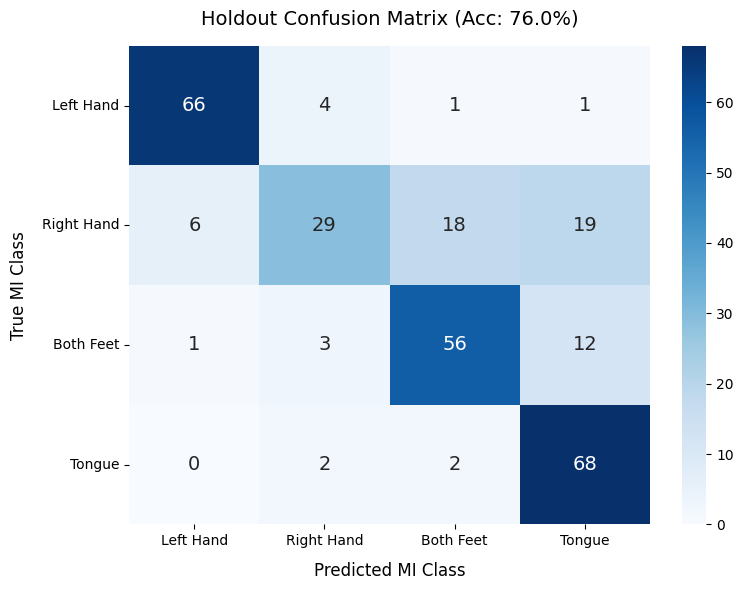

End of 1

Processing Training Data...
Extracting GDF parameters from /kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A09T.gdf...
Setting channel info structure...
Could not determine channel type of the following channels, they will be set as EEG:
EEG-Fz, EEG, EEG, EEG, EEG, EEG, EEG, EEG-C3, EEG, EEG-Cz, EEG, EEG-C4, EEG, EEG, EEG, EEG, EEG, EEG, EEG, EEG-Pz, EEG, EEG, EOG-left, EOG-central, EOG-right
Creating raw.info structure...
Reading 0 ... 673327  =      0.000 ...  2693.308 secs...


/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '769', '770', '771', '772']
Epoch [10/300] | CE Loss: 0.0531 | WC Loss: 3.9001 | Ortho Loss: 0.0089 | Train Acc: 34.10%
Epoch [20/300] | CE Loss: 0.0520 | WC Loss: 4.0790 | Ortho Loss: 0.0057 | Train Acc: 52.01%
Epoch [30/300] | CE Loss: 0.0496 | WC Loss: 4.3001 | Ortho Loss: 0.0061 | Train Acc: 59.79%
Epoch [40/300] | CE Loss: 0.0433 | WC Loss: 4.3510 | Ortho Loss: 0.0059 | Train Acc: 64.44%
Epoch [50/300] | CE Loss: 0.0402 | WC Loss: 4.4729 | Ortho Loss: 0.0074 | Train Acc: 67.64%
Epoch [60/300] | CE Loss: 0.0435 | WC Loss: 4.5609 | Ortho Loss: 0.0099 | Train Acc: 68.54%
Epoch [70/300] | CE Loss: 0.0351 | WC Loss: 4.7246 | Ortho Loss: 0.0113 | Train Acc: 70.90%
Epoch [80/300] | CE Loss: 0.0373 | WC Loss: 4.9146 | Ortho Loss: 0.0129 | Train Acc: 72.22%
Epoch [90/300] | CE Loss: 0.0393 | WC Loss: 5.0808 | Ortho Loss: 0.0153 | Train Acc: 73.82%
Epoch [100/300] | CE Loss: 0.0417 | WC Loss: 5.1932 | Ortho Loss: 

/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '783']
Applying global training normalization to evaluation data...
Reconstructing trial indices from the relative timeline clock...
Labels successfully aligned! Verification Shape: (1440,)
Total unique trials reconstructed from timeline: 288/288

🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)
Target Subject File:  A09E.gdf
Total True Trials:    288
Final True Test Acc:  75.00%



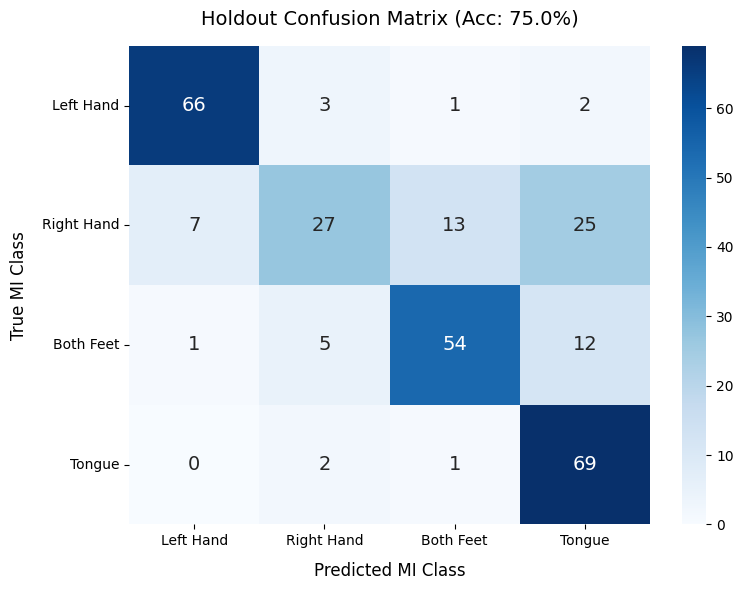

End of 2

Processing Training Data...
Extracting GDF parameters from /kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A09T.gdf...
Setting channel info structure...
Could not determine channel type of the following channels, they will be set as EEG:
EEG-Fz, EEG, EEG, EEG, EEG, EEG, EEG, EEG-C3, EEG, EEG-Cz, EEG, EEG-C4, EEG, EEG, EEG, EEG, EEG, EEG, EEG, EEG-Pz, EEG, EEG, EOG-left, EOG-central, EOG-right
Creating raw.info structure...
Reading 0 ... 673327  =      0.000 ...  2693.308 secs...


/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '769', '770', '771', '772']
Epoch [10/300] | CE Loss: 0.0593 | WC Loss: 3.8725 | Ortho Loss: 0.0095 | Train Acc: 37.29%
Epoch [20/300] | CE Loss: 0.0501 | WC Loss: 4.0721 | Ortho Loss: 0.0050 | Train Acc: 52.64%
Epoch [30/300] | CE Loss: 0.0467 | WC Loss: 4.2009 | Ortho Loss: 0.0056 | Train Acc: 60.97%
Epoch [40/300] | CE Loss: 0.0453 | WC Loss: 4.4586 | Ortho Loss: 0.0103 | Train Acc: 67.22%
Epoch [50/300] | CE Loss: 0.0448 | WC Loss: 4.7116 | Ortho Loss: 0.0096 | Train Acc: 70.90%
Epoch [60/300] | CE Loss: 0.0398 | WC Loss: 4.9017 | Ortho Loss: 0.0105 | Train Acc: 71.81%
Epoch [70/300] | CE Loss: 0.0352 | WC Loss: 5.0377 | Ortho Loss: 0.0095 | Train Acc: 74.24%
Epoch [80/300] | CE Loss: 0.0360 | WC Loss: 5.0810 | Ortho Loss: 0.0095 | Train Acc: 74.86%
Epoch [90/300] | CE Loss: 0.0373 | WC Loss: 5.3097 | Ortho Loss: 0.0103 | Train Acc: 76.11%
Epoch [100/300] | CE Loss: 0.0387 | WC Loss: 5.3828 | Ortho Loss: 

/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '783']
Applying global training normalization to evaluation data...
Reconstructing trial indices from the relative timeline clock...
Labels successfully aligned! Verification Shape: (1440,)
Total unique trials reconstructed from timeline: 288/288

🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)
Target Subject File:  A09E.gdf
Total True Trials:    288
Final True Test Acc:  79.17%



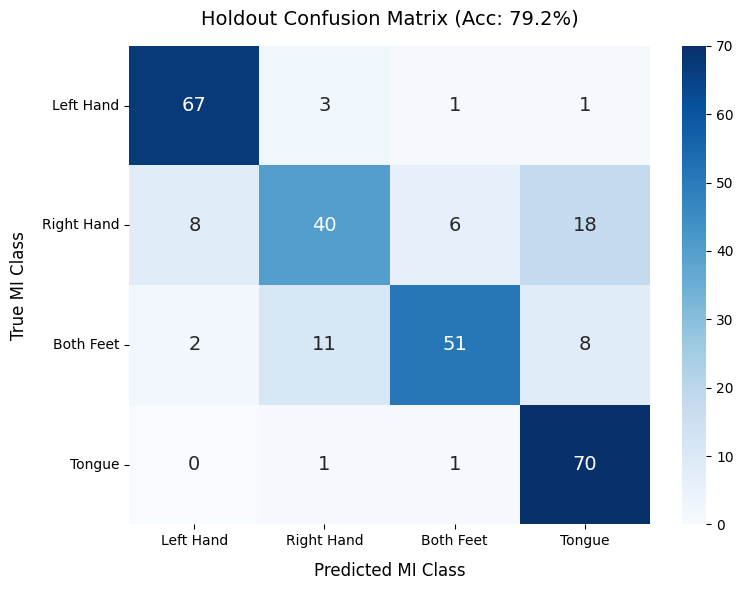

End of 3

Processing Training Data...
Extracting GDF parameters from /kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A09T.gdf...
Setting channel info structure...
Could not determine channel type of the following channels, they will be set as EEG:
EEG-Fz, EEG, EEG, EEG, EEG, EEG, EEG, EEG-C3, EEG, EEG-Cz, EEG, EEG-C4, EEG, EEG, EEG, EEG, EEG, EEG, EEG, EEG-Pz, EEG, EEG, EOG-left, EOG-central, EOG-right
Creating raw.info structure...
Reading 0 ... 673327  =      0.000 ...  2693.308 secs...


/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '769', '770', '771', '772']
Epoch [10/300] | CE Loss: 0.0577 | WC Loss: 3.4407 | Ortho Loss: 0.0263 | Train Acc: 39.24%
Epoch [20/300] | CE Loss: 0.0522 | WC Loss: 3.7934 | Ortho Loss: 0.0171 | Train Acc: 50.28%
Epoch [30/300] | CE Loss: 0.0477 | WC Loss: 3.9114 | Ortho Loss: 0.0144 | Train Acc: 60.14%
Epoch [40/300] | CE Loss: 0.0457 | WC Loss: 4.1281 | Ortho Loss: 0.0114 | Train Acc: 64.58%
Epoch [50/300] | CE Loss: 0.0483 | WC Loss: 4.4149 | Ortho Loss: 0.0093 | Train Acc: 69.93%
Epoch [60/300] | CE Loss: 0.0408 | WC Loss: 4.5195 | Ortho Loss: 0.0085 | Train Acc: 70.62%
Epoch [70/300] | CE Loss: 0.0437 | WC Loss: 4.6155 | Ortho Loss: 0.0079 | Train Acc: 72.01%
Epoch [80/300] | CE Loss: 0.0379 | WC Loss: 4.8251 | Ortho Loss: 0.0082 | Train Acc: 73.12%
Epoch [90/300] | CE Loss: 0.0349 | WC Loss: 4.9067 | Ortho Loss: 0.0085 | Train Acc: 74.10%
Epoch [100/300] | CE Loss: 0.0359 | WC Loss: 5.1310 | Ortho Loss: 

/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '783']
Applying global training normalization to evaluation data...
Reconstructing trial indices from the relative timeline clock...
Labels successfully aligned! Verification Shape: (1440,)
Total unique trials reconstructed from timeline: 288/288

🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)
Target Subject File:  A09E.gdf
Total True Trials:    288
Final True Test Acc:  81.94%



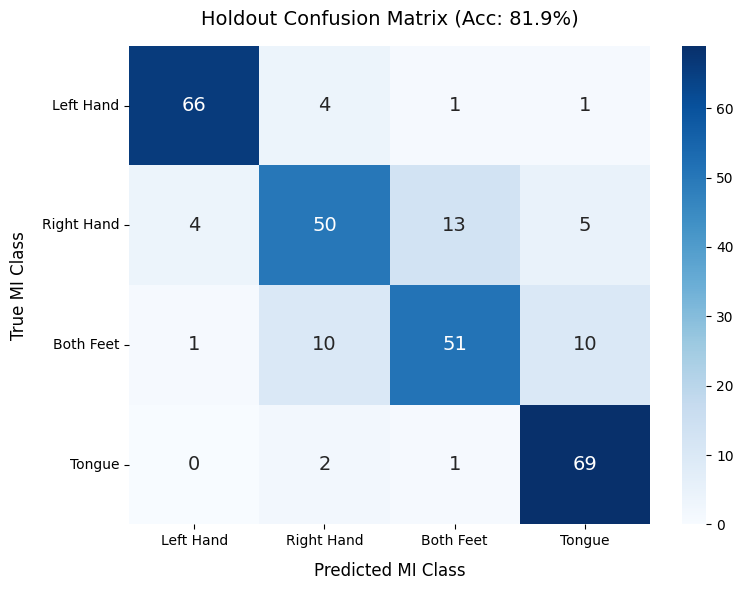

End of 4

Processing Training Data...
Extracting GDF parameters from /kaggle/input/datasets/abdelrahmanyousryyu/bci-comp2a/A09T.gdf...
Setting channel info structure...
Could not determine channel type of the following channels, they will be set as EEG:
EEG-Fz, EEG, EEG, EEG, EEG, EEG, EEG, EEG-C3, EEG, EEG-Cz, EEG, EEG-C4, EEG, EEG, EEG, EEG, EEG, EEG, EEG, EEG-Pz, EEG, EEG, EOG-left, EOG-central, EOG-right
Creating raw.info structure...
Reading 0 ... 673327  =      0.000 ...  2693.308 secs...


/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '769', '770', '771', '772']
Epoch [10/300] | CE Loss: 0.0603 | WC Loss: 4.5889 | Ortho Loss: 0.0088 | Train Acc: 36.81%
Epoch [20/300] | CE Loss: 0.0507 | WC Loss: 4.6353 | Ortho Loss: 0.0060 | Train Acc: 47.08%
Epoch [30/300] | CE Loss: 0.0445 | WC Loss: 4.9108 | Ortho Loss: 0.0079 | Train Acc: 60.90%
Epoch [40/300] | CE Loss: 0.0456 | WC Loss: 5.1656 | Ortho Loss: 0.0117 | Train Acc: 66.04%
Epoch [50/300] | CE Loss: 0.0448 | WC Loss: 5.4728 | Ortho Loss: 0.0125 | Train Acc: 68.47%
Epoch [60/300] | CE Loss: 0.0375 | WC Loss: 5.6813 | Ortho Loss: 0.0142 | Train Acc: 70.76%
Epoch [70/300] | CE Loss: 0.0384 | WC Loss: 5.9772 | Ortho Loss: 0.0154 | Train Acc: 71.81%
Epoch [80/300] | CE Loss: 0.0347 | WC Loss: 6.2350 | Ortho Loss: 0.0158 | Train Acc: 72.71%
Epoch [90/300] | CE Loss: 0.0396 | WC Loss: 6.3633 | Ortho Loss: 0.0168 | Train Acc: 73.68%
Epoch [100/300] | CE Loss: 0.0403 | WC Loss: 6.5784 | Ortho Loss: 

/usr/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


Used Annotations descriptions: ['1023', '1072', '276', '277', '32766', '768', '783']
Applying global training normalization to evaluation data...
Reconstructing trial indices from the relative timeline clock...
Labels successfully aligned! Verification Shape: (1440,)
Total unique trials reconstructed from timeline: 288/288

🏆 OFFICIAL TRIAL-LEVEL EVALUATION RESULTS (T -> E)
Target Subject File:  A09E.gdf
Total True Trials:    288
Final True Test Acc:  78.12%



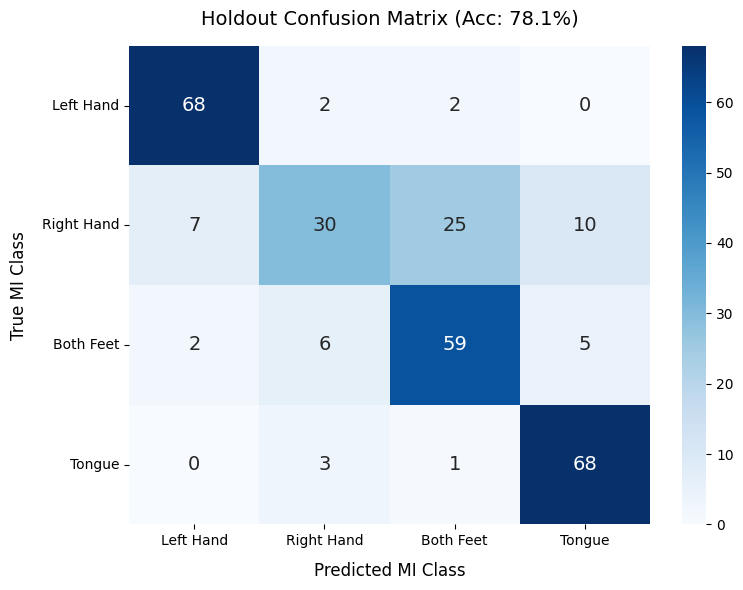

End of 5


In [17]:
lists.append(run_(9, parameters, batch_size, epochs, device, preprocessor, 0.01, 0.001))

# Results

In [18]:
print(lists)

[[81.94444444444444, 83.33333333333333, 82.29166666666667, 81.25, 78.47222222222223], [48.958333333333336, 49.65277777777778, 46.18055555555556, 51.388888888888886, 52.77777777777778], [89.58333333333333, 90.625, 86.11111111111111, 86.45833333333333, 82.98611111111111], [56.25, 60.06944444444444, 63.888888888888886, 56.25, 61.458333333333336], [51.041666666666664, 51.388888888888886, 51.388888888888886, 52.083333333333336, 54.861111111111114], [46.52777777777778, 47.56944444444444, 48.263888888888886, 49.30555555555556, 49.65277777777778], [75.0, 75.69444444444444, 70.48611111111111, 72.22222222222223, 65.625], [77.08333333333333, 79.16666666666667, 77.08333333333333, 76.73611111111111, 76.38888888888889], [76.04166666666667, 75.0, 79.16666666666667, 81.94444444444444, 78.125]]


In [19]:
maxes = [max(row) for row in lists]
print(maxes)

[83.33333333333333, 52.77777777777778, 90.625, 63.888888888888886, 54.861111111111114, 49.65277777777778, 75.69444444444444, 79.16666666666667, 81.94444444444444]


In [20]:
np.mean(maxes) 

np.float64(70.21604938271605)

In [21]:
model = NM_PINN(*parameters)
summary(model)

Layer (type:depth-idx)                   Param #
NM_PINN                                  64
├─Conv2d: 1-1                            1,000
├─BatchNorm2d: 1-2                       16
├─Conv2d: 1-3                            352
├─BatchNorm2d: 1-4                       32
├─ELU: 1-5                               --
├─AdaptiveAvgPool2d: 1-6                 --
├─Dropout: 1-7                           --
├─Linear: 1-8                            132
Total params: 1,596
Trainable params: 1,596
Non-trainable params: 0